# Лабораторная работа №10: Эффективный fine-tuning VLM с помощью Unsloth

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Повторить SFT на том же датасете через Unsloth.
- Сравнить LoRA rank и accumulation короткими runs.
- Построить quality-time-memory benchmark.


## Теоретическая часть

Эта работа оценивает не новый task, а efficiency: wall-clock, peak VRAM, throughput и качество при близких hyperparameters. Ускорение без эквивалентного evaluation не является результатом.


### Математическая постановка

Throughput $=N_{tokens}/T$, peak memory берётся из `torch.cuda.max_memory_allocated()`. Полезно строить Pareto frontier по quality, time и memory.


### Материалы

- [Unsloth docs](https://docs.unsloth.ai/)
- [PEFT](https://huggingface.co/docs/peft/index)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Тот же manifest и та же Qwen2.5-VL, что в работе 9. В Colab требуется совместимая пара версий Unsloth и TRL; зафиксируйте версии и аппаратное обеспечение. `FAST_DEV_RUN=True` всё равно запускает обучение, но только для smoke. Отсутствующие данные или GPU приводят к явной ошибке, а не к демонстрационному benchmark.

In [1]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path(os.getenv('CV_ARTIFACTS', 'artifacts/lab10')); ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_DIR = Path(os.getenv('CV_DATA', 'data/lab9')); DATA_DIR.mkdir(parents=True, exist_ok=True)  # те же изображения, что в работе 09
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
from pathlib import Path
import json, hashlib
from datasets import load_dataset

SCIENCEQA_ID = 'derek-thomas/ScienceQA'
SCIENCEQA_REVISION = 'f18b0a70359ebfb41f658fd564208d0355b013f4'

def prepare_scienceqa(directory=None, smoke=False):
    """Fixed official splits, image-level deduplication, explicitly defined shifts."""
    directory = DATA_DIR if directory is None else directory
    directory = Path(directory).resolve(); directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / ('manifest-smoke.jsonl' if smoke else 'manifest.jsonl')
    limits = {'train': 8 if smoke else 512, 'validation': 4 if smoke else 64,
              'id_test': 4 if smoke else 64, 'ood_test': 4 if smoke else 64,
              'general_test': 4 if smoke else 64}
    if manifest.exists():
        records = [json.loads(s) for s in manifest.read_text(encoding='utf-8').splitlines()]
        if all(Path(r['image']).is_file() for r in records) and all(sum(r['split']==s for r in records)==n for s,n in limits.items()):
            return manifest
    records, seen, counts = [], set(), dict.fromkeys(limits, 0)
    for official in ('train', 'validation', 'test'):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION, split=official, streaming=True)
        for index, row in enumerate(data):
            image = row['image']
            if image is None: continue
            if official != 'test':
                if row['subject'] != 'natural science' or int(row['grade'].removeprefix('grade')) > 6: continue
                split = official
            elif row['subject'] != 'natural science': split = 'general_test'
            elif int(row['grade'].removeprefix('grade')) > 6: split = 'ood_test'
            else: split = 'id_test'
            if counts[split] >= limits[split]: continue
            image = image.convert('RGB')
            digest = hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
            if digest in seen: continue
            seen.add(digest)
            path = directory / f'{digest}.png'; image.save(path)
            answer = int(row['answer']); choices = row['choices']
            question = row['question']+'\n'+'\n'.join(f'{chr(65+i)}. {v}' for i,v in enumerate(choices))+'\nReturn only the letter of the correct option.'
            records.append({'id': f'scienceqa-{official}-{index}', 'split': split,
                            'image': str(path), 'question': question, 'answer': chr(65+answer),
                            'choices': choices, 'answer_index': answer, 'label_type': 'multiple_choice',
                            'license': 'MIT (code license, lupantech/ScienceQA)',
                            'source_url': f'https://huggingface.co/datasets/{SCIENCEQA_ID}/tree/{SCIENCEQA_REVISION}',
                            'subject':row['subject'], 'grade':row['grade'], 'image_sha256':digest})
            counts[split] += 1
            required = [official] if official != 'test' else ['id_test','ood_test','general_test']
            if all(counts[s] == limits[s] for s in required): break
    if counts != limits: raise RuntimeError(f'Insufficient licensed image examples: {counts}; expected {limits}')
    manifest.write_text('\n'.join(json.dumps(r,ensure_ascii=False) for r in records)+'\n', encoding='utf-8')
    (directory/'ATTRIBUTION.md').write_text('ScienceQA — Lu et al., NeurIPS 2022. Dataset distribution: '+SCIENCEQA_ID+'\nRevision: '+SCIENCEQA_REVISION+'\nDataset-card license: CC-BY-SA-4.0, https://creativecommons.org/licenses/by-sa/4.0/\nOriginal project: https://scienceqa.github.io/\nImage subsets and manifests retain attribution; downloaded images are not committed to this course.\nID: natural science grades 1–6; OOD: natural science grades 7–12; general: other subjects. This is an operational shift, not a claim of universal model ability.\n', encoding='utf-8')
    return manifest


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Задание 1. Одинаковые данные для сравнения

*Вес: 1 балл.*

**Постановка.** Загрузите ту же фиксированную ScienceQA-подвыборку через prepare_scienceqa, что в работе 09. Для сравнения библиотек нельзя менять наборы, вопросы или разбиения.

**Результат.** Манифест и изображения.

**Критерий принятия.** ID/хеши записей совпадают с протоколом 09; train и test не пересекаются.


**Одинаковые данные для сравнения**

- **Что делали**: загрузили ту же ScienceQA-подвыборку, что в работе 09 (ревизия f18b0a7), и сверили каждую запись с манифестом 09 по id, split, хешу изображения, вопросу и ответу. Пересчитали хеши всех картинок и проверили, что train и тест не пересекаются.
- **Зачем**: сравнивать Unsloth с LLaMA-Factory честно можно только на тех же вопросах, картинках и разбиениях. Unsloth обещает более быстрое обучение и меньшее использование памяти.
- **Результат**: manifest.jsonl и manifest_check.json. Train 512, validation 64, id_test / ood_test / general_test по 64, всего 768 уникальных изображений. Совпадение с работой 09 — True, пересечений train/test по id и картинкам — 0.

In [2]:
# Артефакт: манифест и изображения из работы SFT
import shutil
from collections import Counter
from PIL import Image

# Те же данные, что в работе 09: та же папка изображений и тот же prepare_scienceqa (ревизия зафиксирована)
MANIFEST = prepare_scienceqa(DATA_DIR, smoke=FAST_DEV_RUN)
records = [json.loads(s) for s in MANIFEST.read_text(encoding='utf-8').splitlines() if s.strip()]

SPLITS = ['train', 'validation', 'id_test', 'ood_test', 'general_test']
EXPECTED = {s: (8 if s == 'train' else 4) if FAST_DEV_RUN else (512 if s == 'train' else 64) for s in SPLITS}
counts = Counter(r['split'] for r in records)
assert dict(counts) == EXPECTED, f'counts {dict(counts)} != expected {EXPECTED}'
assert len({r['id'] for r in records}) == len(records), 'повторяющиеся id'

# 1) Сверка с протоколом 09: id, split, хеш изображения, вопрос и ответ должны совпадать
LAB9_MANIFEST = Path(os.getenv('LAB9_MANIFEST', 'artifacts/lab9/manifest.jsonl'))
if not LAB9_MANIFEST.is_file():
    raise FileNotFoundError(f'Нет манифеста работы 09: {LAB9_MANIFEST}. Без него сравнение с LLaMA-Factory некорректно.')
ref_records = [json.loads(s) for s in LAB9_MANIFEST.read_text(encoding='utf-8').splitlines() if s.strip()]
KEY_FIELDS = ('id', 'split', 'image_sha256', 'question', 'answer', 'answer_index')
key = lambda r: tuple(json.dumps(r[f], ensure_ascii=False) for f in KEY_FIELDS)
ours, ref = [key(r) for r in records], [key(r) for r in ref_records]
if FAST_DEV_RUN:
    # smoke-манифест — подвыборка; каждая запись обязана присутствовать в протоколе 09 без изменений
    ref_set = set(ref)
    missing = [r['id'] for r, k in zip(records, ours) if k not in ref_set]
    assert not missing, f'записи отсутствуют/изменены относительно работы 09: {missing}'
else:
    assert ours == ref, 'манифест не совпадает с протоколом 09 (состав, порядок или содержимое записей)'

# 2) Изображения существуют, и пересчитанный хеш совпадает с записанным
for r in records:
    with Image.open(r['image']) as im:
        img = im.convert('RGB')
    digest = hashlib.sha256(str(img.size).encode() + img.tobytes()).hexdigest()
    assert digest == r['image_sha256'], f"хеш не совпадает: {r['id']}"

# 3) train/validation и тестовые разбиения не пересекаются ни по id, ни по изображениям
fit = [r for r in records if r['split'] in ('train', 'validation')]
test = [r for r in records if r['split'].endswith('_test')]
assert not {r['id'] for r in fit} & {r['id'] for r in test}, 'пересечение id train/test'
assert not {r['image_sha256'] for r in fit} & {r['image_sha256'] for r in test}, 'пересечение изображений train/test'
assert len({r['image_sha256'] for r in records}) == len(records), 'одно изображение в нескольких записях'

# 4) Фиксация: копия манифеста и атрибуции в артефактах работы 10 + хеши для сверки
shutil.copy2(MANIFEST, ARTIFACTS / MANIFEST.name)
shutil.copy2(MANIFEST.parent / 'ATTRIBUTION.md', ARTIFACTS / 'ATTRIBUTION.md')
file_sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
records_sha = hashlib.sha256('\n'.join('|'.join(k) for k in ours).encode('utf-8')).hexdigest()
ref_sha = hashlib.sha256('\n'.join('|'.join(k) for k in ref).encode('utf-8')).hexdigest()
by_split = {s: [r for r in records if r['split'] == s] for s in SPLITS}
save_json('manifest_check.json', {
    'manifest': str(MANIFEST), 'image_dir': str(MANIFEST.parent), 'fast_dev_run': FAST_DEV_RUN,
    'source': SCIENCEQA_ID, 'revision': SCIENCEQA_REVISION,
    'counts': dict(counts), 'expected': EXPECTED, 'unique_images': len({r['image_sha256'] for r in records}),
    'lab9_manifest': str(LAB9_MANIFEST), 'lab9_manifest_file_sha256': file_sha(LAB9_MANIFEST),
    'records_key_sha256': records_sha, 'lab9_records_key_sha256': ref_sha,
    'matches_lab9': records_sha == ref_sha if not FAST_DEV_RUN else 'subset',
    'key_fields': list(KEY_FIELDS), 'train_test_id_overlap': 0, 'train_test_image_overlap': 0,
    'ids_by_split': {s: [r['id'] for r in rs] for s, rs in by_split.items()},
})
print(MANIFEST, dict(counts))
print('совпадает с работой 09:', 'подвыборка' if FAST_DEV_RUN else records_sha == ref_sha)

C:\Users\bogom\OneDrive\Документы\PSY\6 курс\МО\data\lab9\manifest.jsonl {'train': 512, 'validation': 64, 'ood_test': 64, 'general_test': 64, 'id_test': 64}
совпадает с работой 09: True


### Задание 2. Равный вычислительный бюджет

*Вес: 1 балл.*

**Постановка.** Зафиксируйте Qwen2.5-VL-3B-Instruct, GPU, 100 optimizer steps и accumulation 16. Сравнивайте ранги 8 и 16 при одинаковом количестве обработанных примеров.

**Результат.** protocol.json.

**Критерий принятия.** Сохранены GPU, модель, размеры выборок и бюджет; для обеих серий указан один seed.


Фиксируем условия эксперимента

**Равный вычислительный бюджет**

- **Что делали**: записали GPU (RTX 3060, 12 ГБ), модель Qwen2.5-VL-3B-Instruct, версии библиотек и бюджет: 100 optimizer steps, batch 4 × accumulation 4 = 16, 1600 примеров (≈3.1 эпохи). Порядок данных зафиксирован хешем, seed 42 общий для обоих рангов.
- **Зачем**: ранги 8 и 16 (размер матриц адаптера LoRA) должны отличаться только рангом, иначе разницу во времени и качестве нельзя объяснить рангом.
- **Результат**: protocol.json. Отступление от постановки (4 × 4 вместо accumulation 16) записано в файл: effective batch и число примеров сохранены, а раскладка совпадает с работой 09.

In [3]:
# Артефакт: artifacts/protocol.json с GPU, шагами и размером train/test
import platform, importlib.metadata as md
import torch

if not torch.cuda.is_available():
    raise RuntimeError('CUDA GPU не найден: эффективность Unsloth без GPU не измеряется')

def pkg_version(name):
    try: return md.version(name)
    except md.PackageNotFoundError: return None

props = torch.cuda.get_device_properties(0)
GPU = {'name': props.name, 'total_memory_gb': round(props.total_memory / 2**30, 2),
       'capability': f'{props.major}.{props.minor}', 'count': torch.cuda.device_count(),
       'cuda': torch.version.cuda, 'bf16_supported': torch.cuda.is_bf16_supported()}

# Общий бюджет: одинаков для обоих рангов, меняются только r и alpha
MODEL_ID = 'Qwen/Qwen2.5-VL-3B-Instruct'
MAX_STEPS = 2 if FAST_DEV_RUN else 100     # optimizer steps
MICRO_BATCH = 4                             # 4 изображения параллельно в одном forward/backward
GRAD_ACCUM = 4                              # микробатчей на один optimizer step
# Отступление от постановки (1×16): effective batch тот же (16), раскладка 4×4 — как в работе 09 (LLaMA-Factory)
BATCH_DEVIATION = ('Постановка: accumulation 16 (micro_batch 1). Используется micro_batch 4 × accumulation 4: '
                   'effective batch 16 и 1600 примеров сохранены; раскладка совпадает с работой 09, '
                   'что делает сопоставимыми время и память с LLaMA-Factory.')
EFFECTIVE_BATCH = MICRO_BATCH * GRAD_ACCUM
N_EXAMPLES_SEEN = MAX_STEPS * EFFECTIVE_BATCH
TRAIN = dict(learning_rate=1e-4, lr_scheduler='cosine', warmup_ratio=0.1, weight_decay=0.0,
             optimizer='adamw_torch', max_grad_norm=1.0, precision='bf16' if GPU['bf16_supported'] else 'fp16',
             load_in_4bit=True, quantization='bnb nf4 (Unsloth)', gradient_checkpointing='unsloth',
             image_max_pixels=512 * 512, max_seq_length=2048, max_new_tokens=8)
LORA_COMMON = dict(lora_dropout=0.05, bias='none', finetune_vision_layers=False,  # vision tower заморожен, как в работе 09
                   finetune_language_layers=True, finetune_attention_modules=True, finetune_mlp_modules=True)
RUNS = {  # имена папок — как в постановке; alpha = 2·r
    'r8_a16':  {'r': 8,  'lora_alpha': 16, 'dir': 'unsloth_r8_a16'},
    'r16_a16': {'r': 16, 'lora_alpha': 32, 'dir': 'unsloth_r16_a16'},
}

# Один фиксированный порядок примеров на обе серии: перестановки train по эпохам с SEED
train_ids = [r['id'] for r in by_split['train']]
order_rng = random.Random(SEED)
DATA_ORDER = []
while len(DATA_ORDER) < N_EXAMPLES_SEEN:
    perm = train_ids[:]; order_rng.shuffle(perm); DATA_ORDER += perm
DATA_ORDER = DATA_ORDER[:N_EXAMPLES_SEEN]
order_sha = hashlib.sha256('\n'.join(DATA_ORDER).encode('utf-8')).hexdigest()

# Бюджет работы 09 (LLaMA-Factory) — для честного сравнения в последнем задании
lab9_cfg_path = Path('artifacts/lab9/lab9_adapter.run_config.json')  # тот же конфиг, что sft.yaml, но в JSON
if lab9_cfg_path.is_file():
    lf = json.loads(lab9_cfg_path.read_text(encoding='utf-8'))['config']
    lab9_budget = {k: lf.get(k) for k in ('model_name_or_path', 'max_steps', 'per_device_train_batch_size',
                   'gradient_accumulation_steps', 'learning_rate', 'lr_scheduler_type', 'warmup_ratio',
                   'lora_rank', 'lora_alpha', 'lora_dropout', 'lora_target', 'freeze_vision_tower',
                   'quantization_bit', 'image_max_pixels', 'seed')}
    lab9_budget['effective_batch'] = lf['per_device_train_batch_size'] * lf['gradient_accumulation_steps']
    lab9_budget['examples_seen'] = lab9_budget['effective_batch'] * lf['max_steps']
else:
    lab9_budget = None  # baseline отсутствует — отмечается явно

protocol = {
    'model': MODEL_ID, 'seed': SEED, 'fast_dev_run': FAST_DEV_RUN,
    'gpu': GPU, 'platform': platform.platform(), 'python': platform.python_version(),
    'versions': {p: pkg_version(p) for p in ('unsloth', 'unsloth_zoo', 'torch', 'transformers', 'trl',
                                             'peft', 'accelerate', 'bitsandbytes', 'datasets')},
    'data': {'manifest': str(MANIFEST), 'revision': SCIENCEQA_REVISION,
             'split_sizes': {s: len(by_split[s]) for s in SPLITS},
             'train_size': len(by_split['train']),
             'test_sizes': {s: len(by_split[s]) for s in SPLITS if s.endswith('_test')}},
    'budget': {'optimizer_steps': MAX_STEPS, 'grad_accumulation': GRAD_ACCUM, 'micro_batch': MICRO_BATCH,
               'effective_batch': EFFECTIVE_BATCH, 'examples_seen': N_EXAMPLES_SEEN,
               'epochs_equivalent': round(N_EXAMPLES_SEEN / len(train_ids), 3),
               'data_order_sha256': order_sha, 'deviation_from_task': BATCH_DEVIATION},
    'training': TRAIN, 'lora_common': LORA_COMMON,
    'runs': {name: {**cfg, 'seed': SEED, 'data_order_sha256': order_sha, 'optimizer_steps': MAX_STEPS,
                    'effective_batch': EFFECTIVE_BATCH} for name, cfg in RUNS.items()},
    'lab9_llamafactory_budget': lab9_budget if lab9_budget is not None else 'missing',
}
assert len({(c['seed'], c['data_order_sha256'], c['optimizer_steps'], c['effective_batch'])
            for c in protocol['runs'].values()}) == 1, 'серии различаются не только рангом'
save_json('protocol.json', protocol)
print(json.dumps({k: protocol[k] for k in ('model', 'gpu', 'budget')}, ensure_ascii=False, indent=2))

{
  "model": "Qwen/Qwen2.5-VL-3B-Instruct",
  "gpu": {
    "name": "NVIDIA GeForce RTX 3060",
    "total_memory_gb": 12.0,
    "capability": "8.6",
    "count": 1,
    "cuda": "12.8",
    "bf16_supported": true
  },
  "budget": {
    "optimizer_steps": 100,
    "grad_accumulation": 4,
    "micro_batch": 4,
    "effective_batch": 16,
    "examples_seen": 1600,
    "epochs_equivalent": 3.125,
    "data_order_sha256": "450729567f8d21c8978a279f57bd852ed8af620a7ca475487f3b812461423048",
    "deviation_from_task": "Постановка: accumulation 16 (micro_batch 1). Используется micro_batch 4 × accumulation 4: effective batch 16 и 1600 примеров сохранены; раскладка совпадает с работой 09, что делает сопоставимыми время и память с LLaMA-Factory."
  }
}


### Задание 3. Цикл мультимодального SFT

*Вес: 1 балл.*

**Постановка.** Реализуйте train_adapter с UnslothVisionDataCollator, AdamW, накоплением градиентов и ограничением их нормы. Измеряйте время с CUDA synchronize, сохраняйте историю loss и обученный адаптер.

**Результат.** Функция train_adapter.

**Критерий принятия.** На каждый optimizer step приходится accumulation микробатчей; измерения реальны; нечисловой loss вызывает ошибку.


Настраиваем функцию обучения. В работе 9 цикл обучения был скрыт внутри LLaMA-Factory, а в работе 10 мы написали его сами на базе Unsloth. 

**Цикл мультимодального SFT**

- **Что делали**: написали свой цикл обучения на Unsloth: модель в 4-bit, LoRA только на языковой части, UnslothVisionDataCollator считает loss только по ответу. AdamW (lr 1e-4, cosine, warmup 10 %), 4 микробатча на шаг, ограничение нормы градиента 1.0. Время меряется с torch.cuda.synchronize, память — через max_memory_allocated.
- **Зачем**: в работе 09 цикл был скрыт внутри LLaMA-Factory, а здесь каждый шаг и каждое измерение под нашим контролем.
- **Результат**: функции build_lora_model, train_adapter и finished_run. Нечисловой loss останавливает обучение с ошибкой, готовый адаптер повторно не обучается.

In [4]:
# Артефакт: FastVisionModel и измерительный протокол
# unsloth импортируется раньше transformers/peft, иначе его патчи не применяются
from unsloth import FastVisionModel
from unsloth.trainer import UnslothVisionDataCollator
import gc, math
from PIL import Image
from transformers import get_cosine_schedule_with_warmup
from transformers.image_utils import SizeDict

ID2REC = {r['id']: r for r in records}
MAX_PIXELS = TRAIN['image_max_pixels']

def load_image(path):
    """RGB, площадь не больше MAX_PIXELS с сохранением пропорций (как image_max_pixels в работе 09)."""
    img = Image.open(path).convert('RGB')
    w, h = img.size
    if w * h > MAX_PIXELS:
        s = math.sqrt(MAX_PIXELS / (w * h))
        img = img.resize((max(28, int(w * s)), max(28, int(h * s))), Image.BICUBIC)
    return img

def to_conversation(r, with_answer=True):
    msgs = [{'role': 'user', 'content': [{'type': 'image', 'image': load_image(r['image'])},
                                         {'type': 'text', 'text': r['question']}]}]
    if with_answer:
        msgs.append({'role': 'assistant', 'content': [{'type': 'text', 'text': r['answer']}]})
    return {'messages': msgs}

def build_lora_model(run_name):
    """Каждый раз — исходная 4-bit модель + новый LoRA (ранги не наследуют друг друга)."""
    cfg = RUNS[run_name]
    torch.manual_seed(SEED); random.seed(SEED); np.random.seed(SEED)
    model, processor = FastVisionModel.from_pretrained(
        MODEL_ID, load_in_4bit=TRAIN['load_in_4bit'], max_seq_length=TRAIN['max_seq_length'],
        use_gradient_checkpointing=TRAIN['gradient_checkpointing'])
    # transformers 5.x: max_pixels — свойство только для чтения, лимит хранится в size.longest_edge
    ip = processor.image_processor
    ip.size = SizeDict(shortest_edge=ip.size['shortest_edge'], longest_edge=MAX_PIXELS)
    assert ip.size['longest_edge'] == MAX_PIXELS
    model = FastVisionModel.get_peft_model(
        model, r=cfg['r'], lora_alpha=cfg['lora_alpha'], random_state=SEED,
        use_rslora=False, loftq_config=None, **LORA_COMMON)
    return model, processor

def train_adapter(model, processor, run_name, out_dir=None):
    """Ручной цикл SFT: MICRO_BATCH × GRAD_ACCUM микробатчей на optimizer step, AdamW, clip grad norm."""
    out_dir = Path(out_dir or ARTIFACTS / RUNS[run_name]['dir']); out_dir.mkdir(parents=True, exist_ok=True)
    collator = UnslothVisionDataCollator(
        model, processor, max_seq_length=TRAIN['max_seq_length'], train_on_responses_only=True,
        resize='max',  # без собственного ресайза коллатора: лимит площади уже задан load_image и processor
        instruction_part='<|im_start|>user\n', response_part='<|im_start|>assistant\n')  # loss только по ответу

    # Общий порядок данных → микробатчи → группы по GRAD_ACCUM на каждый шаг
    assert len(DATA_ORDER) == MAX_STEPS * GRAD_ACCUM * MICRO_BATCH
    micro = [DATA_ORDER[i:i + MICRO_BATCH] for i in range(0, len(DATA_ORDER), MICRO_BATCH)]
    step_groups = [micro[s * GRAD_ACCUM:(s + 1) * GRAD_ACCUM] for s in range(MAX_STEPS)]
    assert all(len(g) == GRAD_ACCUM and all(len(m) == MICRO_BATCH for m in g) for g in step_groups)

    FastVisionModel.for_training(model); model.train()
    params = [p for p in model.parameters() if p.requires_grad]
    n_trainable = sum(p.numel() for p in params)
    optimizer = torch.optim.AdamW(params, lr=TRAIN['learning_rate'], weight_decay=TRAIN['weight_decay'])
    scheduler = get_cosine_schedule_with_warmup(optimizer, math.ceil(TRAIN['warmup_ratio'] * MAX_STEPS), MAX_STEPS)
    amp_dtype = torch.bfloat16 if TRAIN['precision'] == 'bf16' else torch.float16
    torch.manual_seed(SEED)

    history, tokens_total, tokens_supervised = [], 0, 0
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize(); t0 = time.perf_counter()
    for step, group in enumerate(step_groups, start=1):
        torch.cuda.synchronize(); ts = time.perf_counter()
        optimizer.zero_grad(set_to_none=True)
        micro_losses = []
        for ids in group:
            batch = collator([to_conversation(ID2REC[i]) for i in ids])
            batch = {k: v.to(model.device) if torch.is_tensor(v) else v for k, v in batch.items()}
            with torch.autocast('cuda', dtype=amp_dtype):
                loss = model(**batch).loss
            if not torch.isfinite(loss):
                raise FloatingPointError(f'{run_name}: нечисловой loss {loss.item()} на шаге {step}')
            (loss / GRAD_ACCUM).backward()
            micro_losses.append(loss.item())
            tokens_total += int(batch['attention_mask'].sum())
            tokens_supervised += int((batch['labels'] != -100).sum())
        grad_norm = torch.nn.utils.clip_grad_norm_(params, TRAIN['max_grad_norm'])
        if not torch.isfinite(grad_norm):
            raise FloatingPointError(f'{run_name}: нечисловая норма градиента на шаге {step}')
        lr = scheduler.get_last_lr()[0]
        optimizer.step(); scheduler.step()
        torch.cuda.synchronize()
        history.append({'step': step, 'loss': float(np.mean(micro_losses)), 'micro_batches': len(micro_losses),
                        'grad_norm': float(grad_norm), 'lr': lr, 'step_time_s': time.perf_counter() - ts})
        if step % 10 == 0 or step == MAX_STEPS:
            print(f"[{run_name}] step {step}/{MAX_STEPS} loss={history[-1]['loss']:.4f} "
                  f"gn={history[-1]['grad_norm']:.3f} {history[-1]['step_time_s']:.1f}s")
    torch.cuda.synchronize(); train_time = time.perf_counter() - t0

    assert len(history) == MAX_STEPS and all(h['micro_batches'] == GRAD_ACCUM for h in history)
    model.save_pretrained(out_dir / 'adapter'); processor.save_pretrained(out_dir / 'adapter')
    result = {
        'run': run_name, **RUNS[run_name], 'seed': SEED, 'model': MODEL_ID,
        'optimizer_steps': len(history), 'grad_accumulation': GRAD_ACCUM, 'micro_batch': MICRO_BATCH,
        'effective_batch': EFFECTIVE_BATCH, 'examples_seen': len(history) * EFFECTIVE_BATCH,
        'data_order_sha256': order_sha, 'trainable_params': n_trainable,
        'train_time_s': train_time,
        'peak_memory_allocated_gb': torch.cuda.max_memory_allocated() / 2**30,
        'peak_memory_reserved_gb': torch.cuda.max_memory_reserved() / 2**30,
        'tokens_total': tokens_total, 'tokens_supervised': tokens_supervised,
        'throughput_tokens_per_s': tokens_total / train_time,
        'throughput_examples_per_s': len(history) * EFFECTIVE_BATCH / train_time,
        'final_loss': history[-1]['loss'], 'gpu': GPU['name'], 'history': history,
        'adapter': str(out_dir / 'adapter'),
    }
    (out_dir / 'training.json').write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding='utf-8')
    return result

FORCE_RETRAIN = os.getenv('FORCE_RETRAIN', '0') == '1'   # 1 — переобучить, даже если готовый адаптер есть

def finished_run(run_name):
    """Готовый прогон с тем же протоколом → его training.json; иначе None (значит, нужно обучать)."""
    out_dir = ARTIFACTS / RUNS[run_name]['dir']
    f = out_dir / 'training.json'
    if FORCE_RETRAIN or not (f.is_file() and (out_dir / 'adapter' / 'adapter_config.json').is_file()):
        return None
    res = json.loads(f.read_text(encoding='utf-8'))
    expected = {'optimizer_steps': MAX_STEPS, 'micro_batch': MICRO_BATCH, 'grad_accumulation': GRAD_ACCUM,
                'seed': SEED, 'data_order_sha256': order_sha, 'model': MODEL_ID,
                'r': RUNS[run_name]['r'], 'lora_alpha': RUNS[run_name]['lora_alpha']}
    mismatch = {k: (res.get(k), v) for k, v in expected.items() if res.get(k) != v}
    if mismatch:
        print(f'{run_name}: сохранённый прогон не соответствует протоколу {mismatch} — обучаем заново')
        return None
    return res

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1101 15:23:57.229000 35940 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


🦥 Unsloth Zoo will now patch everything to make training faster!


### Задание 4. LoRA ранга 8

*Вес: 1 балл.*

**Постановка.** Создайте FastVisionModel и LoRA rank 8, alpha 16. Обучите модель по общему протоколу и сохраните адаптер отдельно.

**Результат.** unsloth_r8_a16/adapter и training.json.

**Критерий принятия.** Фактически выполнено 100 optimizer steps; зафиксированы loss, время и пиковая CUDA-память.


**FastVisionModel**. Это класс библиотеки Unsloth для работы с моделями, которые понимают и картинки, и текст (VLM). Сама модель остаётся той же Qwen2.5-VL, а этот класс загружает её и подготавливает с оптимизациями Unsloth.

Обучаем первую модель: LoRA с рангом 8 и alpha 16. 100 шагов

**LoRA ранга 8**

- **Что делали**: создали LoRA r = 8, alpha = 16 поверх исходной модели и обучили её 100 шагов по общему протоколу.
- **Зачем**: получить первый адаптер и измерить его цену: время, память, скорость.
- **Результат**: unsloth_r8_a16/adapter и training.json. 15.0 млн обучаемых параметров. Loss 0.699 → 0.062, время 13.3 мин, пиковая память 4.46 ГБ, 303 tok/s.

In [5]:
# Артефакт: адаптер ранга 8 и измеренные ресурсы
RUN = 'r8_a16'
assert RUNS[RUN]['r'] == 8 and RUNS[RUN]['lora_alpha'] == 16
TRAINING = globals().get('TRAINING', {})
out_dir = ARTIFACTS / RUNS[RUN]['dir']

cached = finished_run(RUN)
if cached is not None:
    # Адаптер уже обучен по этому же протоколу — повторно не обучаем, берём реальные измерения с диска
    TRAINING[RUN] = cached
    print(f'{RUN}: найден готовый адаптер {out_dir / "adapter"} — обучение пропущено (FORCE_RETRAIN=1 для повтора)')
else:
    torch.cuda.synchronize(); t_load = time.perf_counter()
    model, processor = build_lora_model(RUN)          # исходная Qwen2.5-VL-3B (4-bit) + новый LoRA r=8, alpha=16
    torch.cuda.synchronize(); load_time = time.perf_counter() - t_load
    load_memory_gb = torch.cuda.memory_allocated() / 2**30   # веса модели + LoRA до обучения
    model.print_trainable_parameters()

    TRAINING[RUN] = train_adapter(model, processor, RUN)
    TRAINING[RUN].update(model_load_time_s=load_time, model_load_memory_gb=load_memory_gb)
    (out_dir / 'training.json').write_text(json.dumps(TRAINING[RUN], ensure_ascii=False, indent=2), encoding='utf-8')

    # Освобождаем GPU: ранг 16 обучается с исходной модели, не с этого адаптера
    del model, processor
    gc.collect(); torch.cuda.empty_cache()

# Критерий принятия: ровно MAX_STEPS шагов, loss/время/пиковая память записаны, адаптер на диске
res = TRAINING[RUN]
assert res['optimizer_steps'] == MAX_STEPS == len(res['history'])
assert all(np.isfinite(h['loss']) for h in res['history'])
assert all(h['micro_batches'] == GRAD_ACCUM for h in res['history'])
assert res['train_time_s'] > 0 and res['peak_memory_allocated_gb'] > 0
assert (out_dir / 'adapter' / 'adapter_config.json').is_file()
assert any((out_dir / 'adapter').glob('adapter_model.*'))
print(f"{RUN}: steps={res['optimizer_steps']}, loss {res['history'][0]['loss']:.4f} → {res['final_loss']:.4f}, "
      f"time={res['train_time_s'] / 60:.1f} мин, peak={res['peak_memory_allocated_gb']:.2f} ГБ "
      f"(reserved {res['peak_memory_reserved_gb']:.2f}), {res['throughput_tokens_per_s']:.0f} tok/s")

r8_a16: найден готовый адаптер artifacts\lab10\unsloth_r8_a16\adapter — обучение пропущено (FORCE_RETRAIN=1 для повтора)
r8_a16: steps=100, loss 0.6990 → 0.0622, time=13.3 мин, peak=4.46 ГБ (reserved 6.32), 303 tok/s


### Задание 5. LoRA ранга 16

*Вес: 1 балл.*

**Постановка.** Повторите эксперимент с rank 16, alpha 32. Начинайте с исходной модели, а не с адаптера ранга 8.

**Результат.** unsloth_r16_a16/adapter и training.json.

**Критерий принятия.** Меняется только ранг и соответствующий alpha; порядок данных, число шагов и effective batch совпадают.


Вместе с рангом вдвое увеличена и alpha: с 16 до 32. Так отношение alpha/r осталось равным 2, и сила поправки к весам сопоставима с рангом 8. Меняется только «ёмкость» адаптера: 29,9 млн обучаемых параметров вместо 15,0 млн.

**LoRA ранга 16**

- **Что делали**: обучили новый LoRA r = 16, alpha = 32 с исходной модели, а не с адаптера ранга 8. Данные, порядок, шаги и batch те же.
- **Зачем**: проверить, что даёт вдвое большая «ёмкость» адаптера при том же бюджете. Отношение alpha/r = 2 сохранено, поэтому сила поправки сопоставима.
- **Результат**: unsloth_r16_a16/adapter и training.json. 29.9 млн обучаемых параметров. Loss 0.699 → 0.055, время 11.8 мин, пиковая память 4.68 ГБ, 341 tok/s.

In [6]:
# Артефакт: адаптер ранга 16 и измеренные ресурсы
RUN = 'r16_a16'
BASE_RUN = 'r8_a16'
assert RUNS[RUN]['r'] == 16 and RUNS[RUN]['lora_alpha'] == 32
TRAINING = globals().get('TRAINING', {})
if BASE_RUN not in TRAINING:  # после перезапуска ядра берём результат ранга 8 с диска
    TRAINING[BASE_RUN] = json.loads((ARTIFACTS / RUNS[BASE_RUN]['dir'] / 'training.json').read_text(encoding='utf-8'))
out_dir = ARTIFACTS / RUNS[RUN]['dir']

cached = finished_run(RUN)
if cached is not None:
    TRAINING[RUN] = cached
    print(f'{RUN}: найден готовый адаптер {out_dir / "adapter"} — обучение пропущено (FORCE_RETRAIN=1 для повтора)')
else:
    torch.cuda.synchronize(); t_load = time.perf_counter()
    model, processor = build_lora_model(RUN)          # снова исходная Qwen2.5-VL-3B (4-bit) + новый LoRA r=16, alpha=32
    torch.cuda.synchronize(); load_time = time.perf_counter() - t_load
    load_memory_gb = torch.cuda.memory_allocated() / 2**30
    # Адаптер ранга 8 не загружен: у модели ровно один LoRA, и он ранга 16
    assert list(model.peft_config) == ['default'] and model.peft_config['default'].r == 16
    assert model.peft_config['default'].lora_alpha == 32
    model.print_trainable_parameters()

    TRAINING[RUN] = train_adapter(model, processor, RUN)
    TRAINING[RUN].update(model_load_time_s=load_time, model_load_memory_gb=load_memory_gb)
    (out_dir / 'training.json').write_text(json.dumps(TRAINING[RUN], ensure_ascii=False, indent=2), encoding='utf-8')

    del model, processor
    gc.collect(); torch.cuda.empty_cache()

res, base = TRAINING[RUN], TRAINING[BASE_RUN]
assert res['optimizer_steps'] == MAX_STEPS == len(res['history'])
assert all(np.isfinite(h['loss']) for h in res['history'])
assert all(h['micro_batches'] == GRAD_ACCUM for h in res['history'])
assert res['train_time_s'] > 0 and res['peak_memory_allocated_gb'] > 0
assert (out_dir / 'adapter' / 'adapter_config.json').is_file()

# Критерий принятия: отличаются только r и alpha, всё остальное совпадает с рангом 8
SAME = ('seed', 'model', 'optimizer_steps', 'grad_accumulation', 'micro_batch',
        'effective_batch', 'examples_seen', 'data_order_sha256', 'gpu')
diff = {k: (base[k], res[k]) for k in SAME if base[k] != res[k]}
assert not diff, f'серии различаются не только рангом: {diff}'
assert (base['r'], base['lora_alpha']) == (8, 16) and (res['r'], res['lora_alpha']) == (16, 32)
assert base['lora_alpha'] / base['r'] == res['lora_alpha'] / res['r']   # одинаковый масштаб alpha/r
print(f"{RUN}: steps={res['optimizer_steps']}, loss {res['history'][0]['loss']:.4f} → {res['final_loss']:.4f}, "
      f"time={res['train_time_s'] / 60:.1f} мин, peak={res['peak_memory_allocated_gb']:.2f} ГБ "
      f"(reserved {res['peak_memory_reserved_gb']:.2f}), {res['throughput_tokens_per_s']:.0f} tok/s")
print(f"обучаемых параметров: r8={base['trainable_params']:,} / r16={res['trainable_params']:,}")

r16_a16: найден готовый адаптер artifacts\lab10\unsloth_r16_a16\adapter — обучение пропущено (FORCE_RETRAIN=1 для повтора)
r16_a16: steps=100, loss 0.6990 → 0.0550, time=11.8 мин, peak=4.68 ГБ (reserved 6.61), 341 tok/s
обучаемых параметров: r8=14,966,784 / r16=29,933,568


### Задание 6. Траектории оптимизации

*Вес: 1 балл.*

**Постановка.** Постройте график loss по optimizer steps для двух рангов. Сопоставьте число шагов, время и пиковую память, прежде чем делать вывод о полезности большего ранга.

**Результат.** loss_comparison.png и benchmark.json.

**Критерий принятия.** График построен по реальным историям обучения, оси и ранги подписаны; отсутствующие измерения не заменены константой.


**Траектории оптимизации**

- **Что делали**: построили графики loss по шагам для обоих рангов из сохранённых историй и сопоставили время, память и скорость. Первый шаг посчитали отдельно.
- **Зачем**: не сделать вывод «r16 быстрее» по цифре, которая на самом деле объясняется разогревом.
- **Результат**: loss_comparison.png и benchmark.json.
  - первый шаг: r8 — 152 с, r16 — 60 с (компиляция и разогрев ядер);
  - дальше шаг одинаковый: 6.56 и 6.53 с, отношение ×1.005;
  - r16 тратит на 5 % больше памяти, его loss за последние 10 шагов ниже на 0.016.

Разница во времени
- **Компиляция**. На первом шаге Unsloth и PyTorch компилируют GPU-функции под модель («compiling each transformer block» в логе). У r8 это происходило с нуля. Скомпилированное сохраняется в кэш на диске, и r16 переиспользовал большую часть. Его 60 с ушли на то, что зависит от размера адаптера: у LoRA ранга 16 другие размеры матриц.
- **Чтение картинок**. На первом шаге картинки впервые читаются с диска. Ко второму запуску Windows уже держала их в памяти.
- **Разогрев видеокарты**. Видеокарта при первом обращении выделяет память и выбирает лучшие алгоритмы для операций.

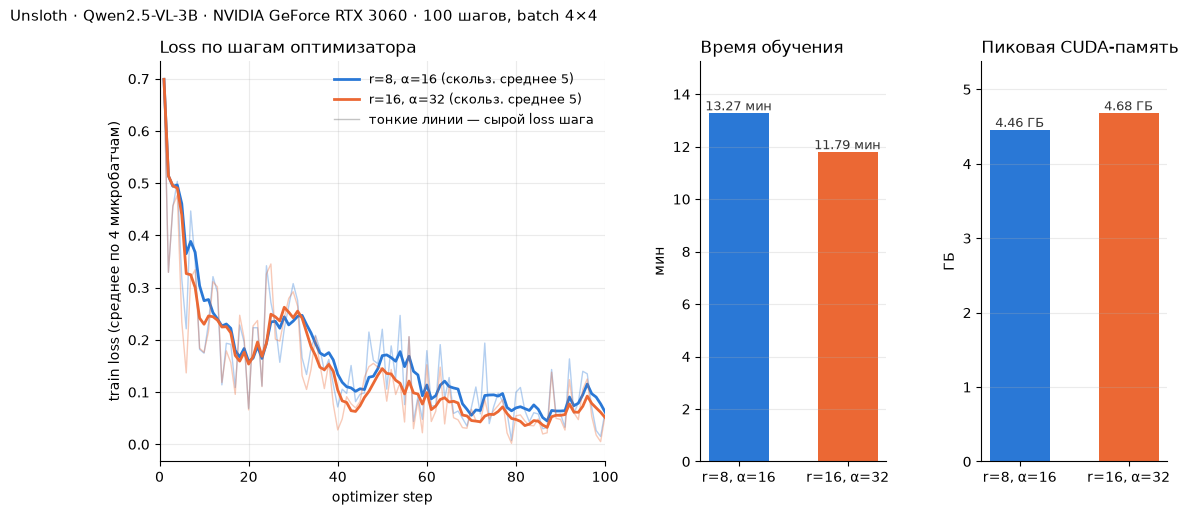

            шаги  время, мин  пик, ГБ   tok/s  loss посл.10  обуч. параметров
r8_a16       100       13.27     4.46     303        0.0785        14,966,784
r16_a16      100       11.79     4.68     341        0.0621        29,933,568
r8_a16: 1-й шаг 152 с (разогрев), далее медиана 6.56 с/шаг
r16_a16: 1-й шаг 60 с (разогрев), далее медиана 6.53 с/шаг
r16/r8: время ×0.888 (без 1-го шага ×1.005), память ×1.050, параметры ×2.00, Δloss(посл.10) = -0.0164


In [7]:
# Артефакт: два реально обученных адаптера в benchmark.json
import matplotlib.pyplot as plt

# Только реальные истории обучения с диска: если прогона нет — ошибка, а не подстановка
runs = {}
for name, cfg in RUNS.items():
    f = ARTIFACTS / cfg['dir'] / 'training.json'
    if not f.is_file():
        raise FileNotFoundError(f'{name}: нет {f} — сначала обучите адаптер')
    runs[name] = json.loads(f.read_text(encoding='utf-8'))
    assert len(runs[name]['history']) == runs[name]['optimizer_steps'] == MAX_STEPS, name

COLORS = {'r8_a16': '#2a78d6', 'r16_a16': '#eb6834'}   # фиксированный цвет за серией
LABEL = {n: f"r={r['r']}, α={r['lora_alpha']}" for n, r in runs.items()}

def smooth(x, k=5):
    """Скользящее среднее по k шагам (только для читаемости, сырые значения тоже на графике)."""
    x = np.asarray(x, float); c = np.cumsum(np.insert(x, 0, 0))
    return np.array([(c[i + 1] - c[max(0, i + 1 - k)]) / (i + 1 - max(0, i + 1 - k)) for i in range(len(x))])

fig = plt.figure(figsize=(13, 5.2))
gs = fig.add_gridspec(1, 3, width_ratios=[2.4, 1, 1], wspace=0.35)
ax = fig.add_subplot(gs[0])
for name, r in runs.items():
    steps = [h['step'] for h in r['history']]; loss = [h['loss'] for h in r['history']]
    ax.plot(steps, loss, color=COLORS[name], lw=1, alpha=0.35)
    ax.plot(steps, smooth(loss), color=COLORS[name], lw=2, label=f'{LABEL[name]} (скольз. среднее 5)')
ax.set_xlabel('optimizer step'); ax.set_ylabel(f'train loss (среднее по {GRAD_ACCUM} микробатчам)')
ax.set_title('Loss по шагам оптимизатора', loc='left')
ax.plot([], [], color='#888888', lw=1, alpha=0.5, label='тонкие линии — сырой loss шага')
ax.set_xlim(0, MAX_STEPS); ax.grid(alpha=0.25); ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=9)

# Время и память — разные шкалы, поэтому отдельные панели, а не вторая ось
for pos, (key, title, unit) in zip((1, 2), [('train_time_s', 'Время обучения', 'мин'),
                                             ('peak_memory_allocated_gb', 'Пиковая CUDA-память', 'ГБ')]):
    a = fig.add_subplot(gs[pos])
    vals = [runs[n][key] / (60 if unit == 'мин' else 1) for n in runs]
    bars = a.bar([LABEL[n] for n in runs], vals, color=[COLORS[n] for n in runs], width=0.55)
    for b, v in zip(bars, vals):
        a.text(b.get_x() + b.get_width() / 2, v, f'{v:.2f} {unit}', ha='center', va='bottom', fontsize=9, color='#333333')
    a.set_title(title, loc='left'); a.set_ylabel(unit); a.margins(y=0.15)
    a.grid(axis='y', alpha=0.25); a.spines[['top', 'right']].set_visible(False)
fig.suptitle(f'Unsloth · Qwen2.5-VL-3B · {GPU["name"]} · {MAX_STEPS} шагов, batch {MICRO_BATCH}×{GRAD_ACCUM}',
             x=0.01, ha='left', fontsize=11)
fig.savefig(ARTIFACTS / 'loss_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# benchmark.json: только измеренные значения; чего нет в training.json — None, а не константа
def tail_mean(r, k=10): return float(np.mean([h['loss'] for h in r['history'][-k:]]))
METRICS = ('optimizer_steps', 'examples_seen', 'effective_batch', 'trainable_params', 'train_time_s',
           'peak_memory_allocated_gb', 'peak_memory_reserved_gb', 'throughput_tokens_per_s',
           'throughput_examples_per_s', 'tokens_total', 'model_load_time_s', 'model_load_memory_gb', 'final_loss')
bench = {'model': MODEL_ID, 'gpu': GPU, 'protocol': 'artifacts/lab10/protocol.json', 'runs': {}}
for name, r in runs.items():
    bench['runs'][name] = {k: r.get(k) for k in METRICS}
    bench['runs'][name].update(r=r['r'], lora_alpha=r['lora_alpha'], first_loss=r['history'][0]['loss'],
                               mean_loss_last10=tail_mean(r), sec_per_step=r['train_time_s'] / len(r['history']),
                               # 1-й шаг включает компиляцию/разогрев ядер Unsloth — отдельно от установившейся скорости
                               first_step_time_s=r['history'][0]['step_time_s'],
                               steady_sec_per_step_median=float(np.median([h['step_time_s'] for h in r['history'][1:]])),
                               steady_time_s=float(sum(h['step_time_s'] for h in r['history'][1:])),
                               adapter=r['adapter'])
a, b = bench['runs']['r8_a16'], bench['runs']['r16_a16']
ratio = lambda k: None if a[k] is None or b[k] is None else b[k] / a[k]
bench['r16_vs_r8'] = {
    'same_steps': a['optimizer_steps'] == b['optimizer_steps'],
    'same_examples_seen': a['examples_seen'] == b['examples_seen'],
    'same_data_order': runs['r8_a16']['data_order_sha256'] == runs['r16_a16']['data_order_sha256'],
    'time_ratio': ratio('train_time_s'), 'steady_time_ratio': ratio('steady_time_s'),
    'peak_memory_ratio': ratio('peak_memory_allocated_gb'),
    'trainable_params_ratio': ratio('trainable_params'),
    'mean_loss_last10_diff': b['mean_loss_last10'] - a['mean_loss_last10'],
    'note': 'train loss — не метрика качества; вывод о пользе ранга 16 — только после EM на ID/OOD',
}
save_json('benchmark.json', bench)

print(f"{'':10}{'шаги':>6}{'время, мин':>12}{'пик, ГБ':>9}{'tok/s':>8}{'loss посл.10':>14}{'обуч. параметров':>18}")
for name, m in bench['runs'].items():
    print(f"{name:10}{m['optimizer_steps']:>6}{m['train_time_s'] / 60:>12.2f}{m['peak_memory_allocated_gb']:>9.2f}"
          f"{m['throughput_tokens_per_s']:>8.0f}{m['mean_loss_last10']:>14.4f}{m['trainable_params']:>18,}")
c = bench['r16_vs_r8']
for name, m in bench['runs'].items():
    print(f"{name}: 1-й шаг {m['first_step_time_s']:.0f} с (разогрев), далее медиана {m['steady_sec_per_step_median']:.2f} с/шаг")
print(f"r16/r8: время ×{c['time_ratio']:.3f} (без 1-го шага ×{c['steady_time_ratio']:.3f}), память ×{c['peak_memory_ratio']:.3f}, "
      f"параметры ×{c['trainable_params_ratio']:.2f}, Δloss(посл.10) = {c['mean_loss_last10_diff']:+.4f}")

**Токены в секунду* (tok/s) показывают, сколько токенов модель обрабатывает за секунду обучения. Это та самая throughput из теории лабораторной: $N_{tokens}/T$.

**Что такое токен**. Это единица, на которые модель разбивает вход: кусочки слов, знаки препинания, служебные метки, а картинка превращается в набор токенов-заполнителей по числу её патчей. Поэтому один пример — это не один токен: вопрос с картинкой легко занимает сотни токенов.

**Значения**: r8 — 303 tok/s, r16 — 341 tok/s.

**Как их читать**. Здесь снова ловушка первого шага. Данные у обоих рангов одинаковые, значит, токенов обработано поровну, а знаменатель у r8 больше из-за долгого первого шага (152 с против 60 с). Поэтому разница 303 и 341 не означает, что r16 быстрее: без первого шага скорость почти одинаковая.<br>
Это также не скорость генерации текста, которую часто указывают для чат-моделей. Здесь считаются токены, пропущенные через модель при обучении, включая всю картинку и вопрос, а большинство из них loss не оценивает.

### Задание 7. Общий интерфейс инференса

*Вес: 1 балл.*

**Постановка.** Реализуйте один greedy-инференс для обоих адаптеров: общие processor, размер изображения, max_new_tokens и извлечение продолжения.

**Результат.** Функция infer.

**Критерий принятия.** Выход не содержит prompt; ответы получаются от активного адаптера на реальном изображении.


Cоздаём единый способ получать ответы от обученных адаптеров. Загружается одна модель, оба адаптера. Убираются лишние предупреждения. Собирается prompt: картинка, вопрос и начало реплики assistant

**Общий интерфейс инференса**

- **Что делали**: загрузили базовую модель один раз и подключили к ней оба адаптера, переключаясь между ними. Декодирование для всех одинаковое: greedy, max_new_tokens = 8, та же подготовка картинки. Из выхода отрезается prompt.
- **Зачем**: разница в ответах должна зависеть только от адаптера, а не от настроек генерации.
- **Результат**: функция infer и inference_config.json. На трёх validation-примерах r8 ответил верно 3 из 3, r16 — 2 из 3. Логиты адаптеров на одном входе различаются (max |Δ| = 1.34), значит, переключение реально работает.

In [8]:
# Артефакт: функция инференса с общим декодированием
from peft import PeftModel

MAX_NEW_TOKENS = TRAIN['max_new_tokens']   # 8 — как в работе 09
ADAPTERS = {name: ARTIFACTS / cfg['dir'] / 'adapter' for name, cfg in RUNS.items()}
for name, path in ADAPTERS.items():
    if not (path / 'adapter_config.json').is_file():
        raise FileNotFoundError(f'{name}: нет обученного адаптера {path}')

# Одна base-модель (те же 4-bit веса, что при обучении) и оба адаптера поверх неё;
# между сериями переключается только активный адаптер — processor и декодирование общие
torch.manual_seed(SEED)
base, infer_processor = FastVisionModel.from_pretrained(
    MODEL_ID, load_in_4bit=TRAIN['load_in_4bit'], max_seq_length=TRAIN['max_seq_length'])
ip = infer_processor.image_processor
ip.size = SizeDict(shortest_edge=ip.size['shortest_edge'], longest_edge=MAX_PIXELS)   # тот же лимит, что в обучении
names = list(ADAPTERS)
infer_model = PeftModel.from_pretrained(base, str(ADAPTERS[names[0]]), adapter_name=names[0])
for name in names[1:]:
    infer_model.load_adapter(str(ADAPTERS[name]), adapter_name=name)
FastVisionModel.for_inference(infer_model)
infer_model.eval()
# Unsloth прописывает в generation_config max_length=128000; длину ответа задаёт max_new_tokens,
# поэтому max_length убираем — иначе transformers печатает предупреждение на каждый generate
base.generation_config.max_length = None
for name in names:
    assert infer_model.peft_config[name].r == RUNS[name]['r'], name

def build_inputs(record):
    """Тот же формат, что в обучении: изображение, затем вопрос; prompt заканчивается репликой assistant."""
    messages = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': record['question']}]}]
    prompt = infer_processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    return infer_processor(text=[prompt], images=[load_image(record['image'])], return_tensors='pt')

@torch.inference_mode()
def infer(adapter, record, max_new_tokens=MAX_NEW_TOKENS):
    """Greedy-ответ активного адаптера; возвращает только продолжение после prompt."""
    infer_model.set_adapter(adapter)
    assert infer_model.active_adapter == adapter
    inputs = build_inputs(record).to(infer_model.device)
    out = infer_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, num_beams=1,
                               temperature=None, top_p=None, top_k=None, use_cache=True,
                               pad_token_id=infer_processor.tokenizer.pad_token_id)
    new_tokens = out[:, inputs['input_ids'].shape[1]:]                     # отрезаем prompt
    return infer_processor.batch_decode(new_tokens, skip_special_tokens=True)[0].strip()

# Проверка на validation (тест не трогаем): реальные изображения, нет prompt в выходе,
# ответ детерминирован, а адаптеры действительно переключаются (разные logits на одном входе)
probe = by_split['validation'][:3]
for r in probe:
    assert Path(r['image']).is_file()
    for name in names:
        a, b = infer(name, r), infer(name, r)
        assert a == b, f'{name}: недетерминированный ответ'
        assert r['question'].split('\n')[0] not in a and 'assistant' not in a, f'{name}: в ответ попал prompt'
        print(f"{r['id']} [{name}]: raw={a!r} gold={r['answer']}")

@torch.inference_mode()
def first_token_logits(adapter, record):
    infer_model.set_adapter(adapter)
    inputs = build_inputs(record).to(infer_model.device)
    return infer_model(**inputs).logits[0, -1].float()

l8, l16 = (first_token_logits(n, probe[0]) for n in names)
adapter_delta = float((l8 - l16).abs().max())
assert adapter_delta > 0, 'адаптеры дают одинаковые logits — переключение не работает'
print(f'max |Δlogits| между {names[0]} и {names[1]} на одном входе: {adapter_delta:.4f}')

save_json('inference_config.json', {
    'decoding': 'greedy', 'do_sample': False, 'num_beams': 1, 'max_new_tokens': MAX_NEW_TOKENS,
    'image_max_pixels': MAX_PIXELS, 'image_preprocessing': 'load_image (как в обучении)',
    'prompt': 'chat template: user=[image, question], add_generation_prompt=True',
    'continuation': 'output_ids[:, len(input_ids):], skip_special_tokens=True, strip()',
    'base_model': MODEL_ID, 'adapters': {n: str(p) for n, p in ADAPTERS.items()},
    'adapter_switch_check_max_abs_logit_delta': adapter_delta,
})

==((====))==  Unsloth 2026.10.6: Fast Qwen2_5_Vl patching. Transformers: 5.17.0.
   \\   /|    NVIDIA GeForce RTX 3060. Num GPUs = 1. Max memory: 12.0 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 8.6. CUDA Toolkit: 12.8. Triton: 3.8.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Skipping model.language_model.layers.1.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.2.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.5.mlp.down_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.30.mlp.down_proj: no quant_state found
Unsloth: compiling each transformer block as one region (Qwen2_5_VLDecoderLayer).
scienceqa-validation-1 

### Задание 8. Метрика и ошибки формата

*Вес: 1 балл.*

**Постановка.** Определите exact match правильной буквы и отдельную долю ответов допустимого формата A–Z. Реализуйте подсчёт по split с явными знаменателями; пустая выборка должна вызывать ошибку.

**Результат.** Функция evaluate_answers.

**Критерий принятия.** Верный ответ даёт EM=1, неверный и лишний текст — EM=0; n равен числу всех примеров split.


Определяем как оценивать ответы модели. Ответ должен быть одной буквой

**Метрика и ошибки формата**

- **Что делали**: задали строгий exact match (ответ ровно равен правильной букве) и отдельно долю ответов в формате одной буквы A–Z. Знаменатель — все примеры split, пустая выборка вызывает ошибку.
- **Зачем**: отделить «модель не знает ответ» от «модель отвечает не в том формате», например «B.» вместо «B».
- **Результат**: функции evaluate_answers, pair_results и paired_table. Проверки пройдены: «B» → 1, «C», «B.», «b», «B. sea otter» → 0.

In [9]:
# Артефакт: контейнер попарных результатов
import re

FORMAT_RE = re.compile(r'[A-Z]')   # допустимый формат ответа: ровно одна заглавная латинская буква

def exact_match(raw, gold):
    """EM=1 только если весь ответ (без пробелов по краям) — правильная буква; 'B.', 'B. otter', 'b' → 0."""
    return int(raw.strip() == gold)

def valid_format(raw):
    return int(FORMAT_RE.fullmatch(raw.strip()) is not None)

def evaluate_answers(predictions, split=None):
    """predictions: [{'id', 'split', 'raw', 'answer'}]. Метрики по каждому split с явными знаменателями.
    split=None — все split из predictions; пустая выборка → ValueError."""
    splits = [split] if split is not None else sorted({p['split'] for p in predictions})
    if not splits:
        raise ValueError('пустая выборка предсказаний')
    report = {}
    for s in splits:
        rows = [p for p in predictions if p['split'] == s]
        n = len(rows)
        if n == 0:
            raise ValueError(f'split {s!r}: нет примеров — метрика не определена')
        em = sum(exact_match(p['raw'], p['answer']) for p in rows)
        fmt = sum(valid_format(p['raw']) for p in rows)
        report[s] = {'n': n, 'em_count': em, 'exact_match': em / n,
                     'format_count': fmt, 'format_rate': fmt / n,
                     # EM среди ответов правильного формата — отделяет «не знает» от «не так отвечает»
                     'em_given_valid_format': em / fmt if fmt else None}
    return report

def pair_results(preds_by_run):
    """Попарный контейнер: для каждого id — ответы всех серий. Наборы id обязаны совпадать."""
    runs_ = list(preds_by_run)
    ids = {r: [p['id'] for p in preds_by_run[r]] for r in runs_}
    for r in runs_:
        assert len(ids[r]) == len(set(ids[r])), f'{r}: повторяющиеся id'
        assert set(ids[r]) == set(ids[runs_[0]]), f'наборы id различаются: {runs_[0]} vs {r}'
    by_id = {r: {p['id']: p for p in preds_by_run[r]} for r in runs_}
    paired = []
    for i in ids[runs_[0]]:
        first = by_id[runs_[0]][i]
        row = {'id': i, 'split': first['split'], 'answer': first['answer']}
        for r in runs_:
            p = by_id[r][i]
            assert (p['split'], p['answer']) == (row['split'], row['answer']), f'{i}: расхождение split/ответа'
            row[f'{r}_raw'] = p['raw']; row[f'{r}_em'] = exact_match(p['raw'], p['answer'])
        paired.append(row)
    return paired

def paired_table(paired, a, b):
    """Таблица согласия двух серий по split: оба верны / только a / только b / оба неверны."""
    out = {}
    for s in sorted({r['split'] for r in paired}):
        rows = [r for r in paired if r['split'] == s]
        if not rows:
            raise ValueError(f'split {s!r}: пусто')
        ea, eb = [r[f'{a}_em'] for r in rows], [r[f'{b}_em'] for r in rows]
        out[s] = {'n': len(rows), 'both_correct': sum(x and y for x, y in zip(ea, eb)),
                  f'only_{a}': sum(x and not y for x, y in zip(ea, eb)),
                  f'only_{b}': sum(y and not x for x, y in zip(ea, eb)),
                  'both_wrong': sum(not x and not y for x, y in zip(ea, eb))}
    return out

# --- Проверки критерия принятия ---
assert exact_match('B', 'B') == 1 and exact_match(' B\n', 'B') == 1
assert exact_match('C', 'B') == 0                       # неверный ответ
assert exact_match('B. sea otter', 'B') == 0            # лишний текст
assert exact_match('B.', 'B') == 0 and exact_match('b', 'B') == 0 and exact_match('', 'B') == 0
assert valid_format('Z') == 1 and valid_format('B.') == 0 and valid_format('AB') == 0 and valid_format('') == 0

toy = [{'id': '1', 'split': 'id_test', 'raw': 'A', 'answer': 'A'},
       {'id': '2', 'split': 'id_test', 'raw': 'B', 'answer': 'A'},
       {'id': '3', 'split': 'id_test', 'raw': 'A. cat', 'answer': 'A'},
       {'id': '4', 'split': 'ood_test', 'raw': 'C', 'answer': 'C'}]
rep = evaluate_answers(toy)
assert rep['id_test'] == {'n': 3, 'em_count': 1, 'exact_match': 1 / 3, 'format_count': 2,
                          'format_rate': 2 / 3, 'em_given_valid_format': 0.5}
assert rep['ood_test']['n'] == 1 and rep['ood_test']['exact_match'] == 1.0
for bad in ([], toy[:3]):
    try:
        evaluate_answers(bad, split='ood_test' if bad else None)
        raise AssertionError('пустая выборка не вызвала ошибку')
    except ValueError:
        pass

toy_b = [dict(p, raw=p['answer']) for p in toy]           # вторая «серия» отвечает всегда верно
pt = paired_table(pair_results({'r8_a16': toy, 'r16_a16': toy_b}), 'r8_a16', 'r16_a16')
assert pt['id_test'] == {'n': 3, 'both_correct': 1, 'only_r8_a16': 0, 'only_r16_a16': 2, 'both_wrong': 0}
print('evaluate_answers: проверки пройдены')

evaluate_answers: проверки пройдены


### Задание 9. Качество двух адаптеров

*Вес: 1 балл.*

**Постановка.** Примените оба адаптера к одним ID/OOD изображениям и рассчитайте согласованные метрики. Сохраните исходный текст каждого ответа.

**Результат.** predictions_r8_a16.jsonl и predictions_r16_a16.jsonl.

**Критерий принятия.** Наборы ID совпадают между сериями; отчёт содержит exact match, format rate и n на ID/OOD.


**Качество двух адаптеров**

- **Что делали**: прогнали оба адаптера на одних и тех же 128 тестовых картинках (64 ID и 64 OOD) и сохранили исходный текст каждого ответа. Сравнили ответы попарно.
- **Зачем**: измерить качество рангов на одинаковых данных.
- **Результат**: predictions_r8_a16.jsonl и predictions_r16_a16.jsonl.
  - r8: EM 0.922 на ID и 0.703 на OOD; r16: 0.953 и 0.719;
  - формат 100 % у обоих;
  - попарно r16 исправил 2 ответа на ID и 1 на OOD и ни разу не ошибся там, где r8 был прав.

In [10]:
# Артефакт: файлы предсказаний ID/OOD test
EVAL_SPLITS = ['id_test', 'ood_test']
EVAL = [r for s in EVAL_SPLITS for r in by_split[s]]          # один и тот же список для обеих серий
EVAL_IDS = [r['id'] for r in EVAL]
assert len(EVAL_IDS) == len(set(EVAL_IDS)) and EVAL, 'пустой или повторяющийся тестовый набор'
FORCE_REINFER = os.getenv('FORCE_REINFER', '0') == '1'

def read_jsonl(path):
    return [json.loads(s) for s in Path(path).read_text(encoding='utf-8').splitlines() if s.strip()]

def predict_split(run_name):
    """Ответы адаптера на все ID/OOD изображения; сохраняется исходный текст ответа."""
    path = ARTIFACTS / f'predictions_{run_name}.jsonl'
    if path.is_file() and not FORCE_REINFER:
        rows = read_jsonl(path)
        if [p['id'] for p in rows] == EVAL_IDS and all(p['image_sha256'] == r['image_sha256'] for p, r in zip(rows, EVAL)):
            return rows
    rows = []
    for r in EVAL:
        torch.cuda.synchronize(); t = time.perf_counter()
        raw = infer(run_name, r)
        torch.cuda.synchronize(); dt = time.perf_counter() - t
        rows.append({'id': r['id'], 'split': r['split'], 'image': r['image'], 'image_sha256': r['image_sha256'],
                     'question': r['question'], 'answer': r['answer'], 'n_choices': len(r['choices']),
                     'raw': raw,                                         # исходный текст как есть
                     'em': exact_match(raw, r['answer']), 'valid_format': valid_format(raw),
                     'adapter': run_name, 'latency_s': dt})
    path.write_text('\n'.join(json.dumps(p, ensure_ascii=False) for p in rows) + '\n', encoding='utf-8')
    return rows

PREDS = {name: predict_split(name) for name in RUNS}

# Критерий принятия: наборы ID совпадают между сериями (и с манифестом)
for name, rows in PREDS.items():
    assert [p['id'] for p in rows] == EVAL_IDS, f'{name}: набор id отличается'
paired = pair_results(PREDS)

quality = {'splits': EVAL_SPLITS, 'n_by_split': {s: len(by_split[s]) for s in EVAL_SPLITS},
           'metric': 'exact match: ответ после strip() == правильная буква; format: ровно одна буква A–Z',
           'runs': {}, 'paired': paired_table(paired, 'r8_a16', 'r16_a16')}
for name, rows in PREDS.items():
    rep = evaluate_answers(rows)
    for s in EVAL_SPLITS:
        assert rep[s]['n'] == len(by_split[s]), f'{name}/{s}: n не равен размеру split'
    quality['runs'][name] = {
        **rep, 'mean_latency_s': float(np.mean([p['latency_s'] for p in rows])) if 'latency_s' in rows[0] else None,
        'invalid_format_examples': [p['raw'] for p in rows if not p['valid_format']][:10]}
save_json('quality_report.json', quality)

print(f"\n{'серия':10}{'split':10}{'n':>5}{'EM':>8}{'format':>9}{'EM | формат ок':>16}")
for name in RUNS:
    for s in EVAL_SPLITS:
        m = quality['runs'][name][s]
        cond = '—' if m['em_given_valid_format'] is None else f"{m['em_given_valid_format']:.3f}"
        print(f"{name:10}{s:10}{m['n']:>5}{m['exact_match']:>8.3f}{m['format_rate']:>9.3f}{cond:>16}")
print('\nпопарно (r8 vs r16):')
for s, t in quality['paired'].items():
    print(f"  {s}: оба верны {t['both_correct']}, только r8 {t['only_r8_a16']}, "
          f"только r16 {t['only_r16_a16']}, оба неверны {t['both_wrong']} (n={t['n']})")


серия     split         n      EM   format  EM | формат ок
r8_a16    id_test      64   0.922    1.000           0.922
r8_a16    ood_test     64   0.703    1.000           0.703
r16_a16   id_test      64   0.953    1.000           0.953
r16_a16   ood_test     64   0.719    1.000           0.719

попарно (r8 vs r16):
  id_test: оба верны 59, только r8 0, только r16 2, оба неверны 3 (n=64)
  ood_test: оба верны 45, только r8 0, только r16 1, оба неверны 18 (n=64)


### Задание 10. Сравнение подходов

*Вес: 1 балл.*

**Постановка.** Сопоставьте качество двух рангов и результат LLaMA-Factory из работы 09. Скорость библиотек сравнивайте только при одинаковых GPU, шагах, effective batch и обучаемых модулях. Отсутствующий baseline обозначьте явно.

**Результат.** comparison.json и вывод.

**Критерий принятия.** Не заявлен speedup по несопоставимым измерениям; отсутствие baseline не выдано за нулевое качество; для полного сравнения приложен результат 09.


**Сравнение подходов**

- **Что делали**: свели качество двух рангов и LLaMA-Factory из работы 09 с 95 % интервалами Уилсона. Скорость библиотек сравнили по шагам без первого и без пауз на оценку: GPU, шаги, effective batch и обучаемые модули совпадают.
- **Зачем**: проверить, даёт ли Unsloth обещанное ускорение без потери качества.
- **Результат**: comparison.json.
  - ID: r8 0.922, r16 0.953, LLaMA-Factory 0.891; OOD: 0.703, 0.719, 0.703. Интервалы перекрываются, различия не доказаны;
  - время: LLaMA-Factory 612 с, Unsloth 644 с, Unsloth на 5 % медленнее. Разница не большая. Вероятные причины: dropout 0.05 отключает быстрые ядра Unsloth. В замер Unsloth входит подготовака данных, такая как: чтение картинки с диска и уменьшенеие её размера; сборка диалога и токенизация, LLaMA-Factory делает токенизацию заранее. Квантование различается, у Unsloth часть слоев не квантована;
  - память LLaMA-Factory не измерялась и помечена как отсутствующая, а не как 0.

  Причины замедления:


In [11]:
# Артефакт: artifacts/comparison.json с явным отсутствующим baseline
LAB9 = Path(os.getenv('LAB9_ARTIFACTS', 'artifacts/lab9'))
MISSING = 'missing'   # отсутствующее измерение помечается явно, а не 0

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return [round(c - h, 4), round(c + h, 4)]

def quality_block(rows):
    rep = evaluate_answers(rows)
    return {s: {**rep[s], 'em_ci95_wilson': wilson(rep[s]['em_count'], rep[s]['n'])} for s in EVAL_SPLITS}

# --- 1. Качество Unsloth r8 / r16 (из сохранённых предсказаний) ---
PREDS = {n: read_jsonl(ARTIFACTS / f'predictions_{n}.jsonl') for n in RUNS}
quality = {f'unsloth_{n}': quality_block(rows) for n, rows in PREDS.items()}

# --- 2. Baseline LLaMA-Factory из работы 09: те же ответы, пересчитанные ТОЙ ЖЕ метрикой ---
lab9_pred_path = LAB9 / 'predictions.jsonl'
lab9_available = lab9_pred_path.is_file()
if lab9_available:
    lab9_rows = [p for p in read_jsonl(lab9_pred_path) if p['split'] in EVAL_SPLITS]
    by_id9 = {p['id']: p for p in lab9_rows}
    assert set(by_id9) == set(EVAL_IDS), 'тестовые id работы 09 не совпадают с работой 10'
    for r in EVAL:   # те же вопросы и правильные ответы
        p = by_id9[r['id']]
        assert p['gold'] == r['answer'], r['id']
        assert p['question_sha256'] == hashlib.sha256(r['question'].encode('utf-8')).hexdigest(), r['id']
    as_rows = lambda key: [{'id': r['id'], 'split': r['split'], 'answer': r['answer'], 'raw': by_id9[r['id']][key]}
                           for r in EVAL]
    LF_ROWS = as_rows('sft_raw')
    quality['llamafactory_r8_a16_lab09'] = quality_block(LF_ROWS)
    quality['base_no_adapter_lab09'] = quality_block(as_rows('base_raw'))   # справочно: модель без адаптера
    paired_lf = paired_table(pair_results({'lf_r8': LF_ROWS, 'unsloth_r8': PREDS['r8_a16']}), 'lf_r8', 'unsloth_r8')
else:
    quality['llamafactory_r8_a16_lab09'] = MISSING
    quality['base_no_adapter_lab09'] = MISSING
    paired_lf = MISSING

# --- 3. Скорость: сравнима ли постановка? ---
bench_ = json.loads((ARTIFACTS / 'benchmark.json').read_text(encoding='utf-8'))
u8 = bench_['runs']['r8_a16']
lab9_cfg_file = LAB9 / 'lab9_adapter.run_config.json'
lab9_ver_file = LAB9 / 'version.json'
lab9_res_file = LAB9 / 'lab9_adapter' / 'all_results.json'
lab9_log_file = LAB9 / 'train.log'

def parse_lf_steady_time(log_path, steps):
    """Чистое время шагов 2..N из tqdm-строк train.log: без 1-го шага (разогрев) и без пауз
    на eval/сохранение чекпоинтов (повторные строки того же шага). None, если лог не разобран."""
    if not log_path.is_file():
        return None
    text = log_path.read_text(encoding='utf-8', errors='ignore').replace('\r', '\n')
    pat = re.compile(rf'\|\s*(\d+)/{steps} \[(\d+):(\d+)(?::(\d+))?')
    seen = {}
    for m in pat.finditer(text):
        k = int(m.group(1)); a, b, c = m.group(2), m.group(3), m.group(4)
        sec = int(a) * 3600 + int(b) * 60 + int(c) if c else int(a) * 60 + int(b)
        seen.setdefault(k, []).append(sec)
    if 1 not in seen or steps not in seen:
        return None
    pauses = sum(max(v) - min(v) for k, v in seen.items() if 1 < k < steps)   # eval + save внутри шагов
    return min(seen[steps]) - max(seen[1]) - pauses

if lab9_cfg_file.is_file() and lab9_ver_file.is_file():
    lf_cfg = json.loads(lab9_cfg_file.read_text(encoding='utf-8'))['config']
    lf_ver = json.loads(lab9_ver_file.read_text(encoding='utf-8'))
    lf_res = json.loads(lab9_res_file.read_text(encoding='utf-8')) if lab9_res_file.is_file() else {}
    lf_trainable = None
    if lab9_log_file.is_file():
        m = re.search(r'Number of trainable parameters = ([\d,]+)', lab9_log_file.read_text(encoding='utf-8', errors='ignore'))
        lf_trainable = int(m.group(1).replace(',', '')) if m else None
    lf_steady = parse_lf_steady_time(lab9_log_file, lf_cfg['max_steps'])
    lf = {
        'gpu': lf_ver['train_env_packages'].get('gpu'), 'optimizer_steps': lf_cfg['max_steps'],
        'effective_batch': lf_cfg['per_device_train_batch_size'] * lf_cfg['gradient_accumulation_steps'],
        'batch_layout': f"{lf_cfg['per_device_train_batch_size']}x{lf_cfg['gradient_accumulation_steps']}",
        'trainable_params': lf_trainable, 'freeze_vision_tower': lf_cfg['freeze_vision_tower'],
        'lora_target': lf_cfg['lora_target'], 'r': lf_cfg['lora_rank'], 'lora_alpha': lf_cfg['lora_alpha'],
        'train_runtime_s_incl_eval_and_saves': lf_res.get('train_runtime', MISSING),
        'steady_time_s_steps_2_to_N': lf_steady if lf_steady is not None else MISSING,
        'peak_memory_gb': MISSING,   # в работе 09 не измерялась
        'quantization': 'bnb NF4 + double quant при загрузке оригинальных весов',
    }
    checks = {
        'same_gpu': lf['gpu'] == GPU['name'],
        'same_steps': lf['optimizer_steps'] == u8['optimizer_steps'],
        'same_effective_batch': lf['effective_batch'] == u8['effective_batch'],
        'same_trainable_modules': lf['trainable_params'] == u8['trainable_params'] and lf['freeze_vision_tower'],
        'same_rank': (lf['r'], lf['lora_alpha']) == (RUNS['r8_a16']['r'], RUNS['r8_a16']['lora_alpha']),
    }
    speed_comparable = all(checks.values()) and lf_steady is not None
else:
    lf, checks, speed_comparable = MISSING, MISSING, False

speed = {'conditions_checked': checks, 'comparable': speed_comparable,
         'pair': 'Unsloth r8_a16 vs LLaMA-Factory r8_a16 (только одинаковый ранг)',
         'r16_vs_llamafactory': 'не сравнивается: разное число обучаемых параметров',
         'remaining_differences': [
             'квантование: Unsloth dynamic 4-bit (часть слоёв в 16 бит) vs bnb NF4 при загрузке (работа 09)',
             'lora_dropout=0.05 отключает часть быстрых ядер Unsloth — его скорость здесь оценка снизу',
             'время LLaMA-Factory восстановлено по tqdm-логу с точностью ~1–2 с'],
         'unsloth_r8': {'steady_time_s_steps_2_to_N': u8['steady_time_s'], 'first_step_s': u8['first_step_time_s'],
                        'train_time_s_total': u8['train_time_s'], 'peak_memory_gb': u8['peak_memory_allocated_gb']},
         'llamafactory_r8': lf}
if speed_comparable:
    speed['steady_speedup_unsloth_vs_lf'] = lf_steady / u8['steady_time_s']
    speed['memory_comparison'] = 'не выполняется: пиковая память в работе 09 не измерялась'
else:
    speed['steady_speedup_unsloth_vs_lf'] = None
    speed['reason'] = 'условия не совпадают или baseline отсутствует — speedup не заявляется'

comparison = {'eval_splits': EVAL_SPLITS, 'n_by_split': {s: len(by_split[s]) for s in EVAL_SPLITS},
              'metric': 'строгий exact match (ответ == буква) и format rate; ответы работы 09 пересчитаны той же функцией',
              'baseline_lab09_available': lab9_available, 'quality': quality,
              'paired_lf_vs_unsloth_r8': paired_lf,
              'paired_unsloth_r8_vs_r16': paired_table(pair_results(PREDS), 'r8_a16', 'r16_a16'),
              'speed': speed, 'lab09_artifacts': str(LAB9)}

# --- 4. Вывод: формулируется из чисел, а не заранее ---
print(f"{'модель':30}" + ''.join(f"{s + ' EM':>22}{'fmt':>7}" for s in EVAL_SPLITS))
for name, q in quality.items():
    if q == MISSING:
        print(f'{name:30}  baseline отсутствует (не 0)'); continue
    print(f'{name:30}' + ''.join(f"{q[s]['exact_match']:>8.3f} [{q[s]['em_ci95_wilson'][0]:.2f}–{q[s]['em_ci95_wilson'][1]:.2f}]"
                                 f"{q[s]['format_rate']:>7.2f}" for s in EVAL_SPLITS))
conclusion = []
q8, q16 = quality['unsloth_r8_a16'], quality['unsloth_r16_a16']
for s in EVAL_SPLITS:
    d = q16[s]['exact_match'] - q8[s]['exact_match']
    overlap = not (q16[s]['em_ci95_wilson'][0] > q8[s]['em_ci95_wilson'][1] or q8[s]['em_ci95_wilson'][0] > q16[s]['em_ci95_wilson'][1])
    conclusion.append(f"{s}: r16 − r8 = {d:+.3f} EM (n={q8[s]['n']}); "
                      + ('интервалы перекрываются — различие не доказано' if overlap else 'интервалы не перекрываются'))
if lab9_available:
    for s in EVAL_SPLITS:
        d = q8[s]['exact_match'] - quality['llamafactory_r8_a16_lab09'][s]['exact_match']
        conclusion.append(f"{s}: Unsloth r8 − LLaMA-Factory r8 = {d:+.3f} EM")
else:
    conclusion.append('Baseline LLaMA-Factory (работа 09) отсутствует: сравнение качества с ним не выполнено')
if speed_comparable:
    sp = speed['steady_speedup_unsloth_vs_lf']
    conclusion.append(f"Скорость (GPU, шаги, effective batch и обучаемые модули совпадают; без 1-го шага и eval): "
                      f"LLaMA-Factory {lf_steady:.0f} с vs Unsloth {u8['steady_time_s']:.0f} с → ускорение Unsloth ×{sp:.2f} "
                      f"({'быстрее' if sp > 1 else 'медленнее'} на {abs(sp - 1) * 100:.0f}%). "
                      f"Квантование и dropout-режим различаются — это не чистый эффект библиотеки.")
else:
    conclusion.append('Speedup не заявляется: ' + speed['reason'])
conclusion.append('Пиковая память LLaMA-Factory не измерялась — сравнение памяти не выполняется.')
comparison['conclusion'] = conclusion
save_json('comparison.json', comparison)
print('\nВывод:'); print('\n'.join('• ' + c for c in conclusion))

модель                                    id_test EM    fmt           ood_test EM    fmt
unsloth_r8_a16                   0.922 [0.83–0.97]   1.00   0.703 [0.58–0.80]   1.00
unsloth_r16_a16                  0.953 [0.87–0.98]   1.00   0.719 [0.60–0.81]   1.00
llamafactory_r8_a16_lab09        0.891 [0.79–0.95]   1.00   0.703 [0.58–0.80]   1.00
base_no_adapter_lab09            0.812 [0.70–0.89]   0.91   0.547 [0.43–0.66]   0.95

Вывод:
• id_test: r16 − r8 = +0.031 EM (n=64); интервалы перекрываются — различие не доказано
• ood_test: r16 − r8 = +0.016 EM (n=64); интервалы перекрываются — различие не доказано
• id_test: Unsloth r8 − LLaMA-Factory r8 = +0.031 EM
• ood_test: Unsloth r8 − LLaMA-Factory r8 = +0.000 EM
• Скорость (GPU, шаги, effective batch и обучаемые модули совпадают; без 1-го шага и eval): LLaMA-Factory 612 с vs Unsloth 644 с → ускорение Unsloth ×0.95 (медленнее на 5%). Квантование и dropout-режим различаются — это не чистый эффект библиотеки.
• Пиковая память LLaMA-Factory н

### Задание 11. Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

Мы проверяем, помогает ли дообучение на чужом предмете так же, как на своём. Модель дообучалась только на natural science 1–6 классов, поэтому есть подозрение, что адаптер улучшает именно этот предмет, а на других даёт разве что правильный формат ответа. Новых обучений здесь нет.

Гипотезы:
- H1: прирост от дообучения на чужом предмете меньше, чем на своём, для обоих рангов.
- H2: больший ранг вне своего предмета не помогает: разница r16 − r8 на чужом предмете не больше, чем на своём.
- H0: ни прирост, ни эффект ранга от предмета не зависят.

**Творческий бонус: перенос на чужой предмет**

- **Что делали**: без нового обучения применили base, r8 и r16 к 64 вопросам по social science (general_test) и сравнили прирост от SFT со своим предметом (id_test, natural science). Разницу оценили парным bootstrap.
- **Зачем**: проверить, учит ли адаптер предмету или в основном формату ответа.
- **Результат**: bonus.md и bonus_summary.json.
  - прирост на своём предмете +0.312 (r8) и +0.344 (r16), на чужом +0.203 у обоих;
  - разница +0.109 [−0.062; +0.281] и +0.141 [−0.016; +0.297]: направление совпадает, но незначимо, интервалы содержат 0;
  - на чужом предмете r16 − r8 = 0, H2 подтверждена; из 13 исправленных ответов 12 — исправление формата.

In [12]:
# Творческое мини-исследование: перенос SFT-адаптеров за пределы предмета обучения
#
# Гипотеза сформулирована ДО просмотра результатов на тесте, только по составу train (protocol/manifest):
# все 512 train-примеров — natural science, 1–6 классы. Адаптеры LoRA учатся на ответах-буквах только этого предмета.
#   H1: прирост EM от SFT относительно base на чужом предмете (general_test: social/language science) меньше,
#       чем на том же предмете (id_test): DiD = gain(id) − gain(general) > 0 для обоих рангов.
#   H2: больший ранг не помогает вне предмета: Δ(r16 − r8) на general_test не больше, чем на id_test.
#   H0: прирост от SFT и эффект ранга не зависят от предмета.
# Дополнительные реальные входы: general_test (64 изображения ScienceQA из официального test, другие предметы).
# В основном эксперименте работы 10 этот split не использовался; id_test/ood_test для выбора гипотезы не смотрели.
import collections
LAB9 = globals().get('LAB9', Path('artifacts/lab9'))
MISSING = 'missing'

HYPOTHESIS = {
    'H1': 'gain_vs_base(id_test) − gain_vs_base(general_test) > 0 для r8 и r16 (SFT переносится на другой предмет хуже)',
    'H2': '[EM_r16 − EM_r8](general_test) ≤ [EM_r16 − EM_r8](id_test) (больший ранг не помогает вне предмета)',
    'decision_rule': 'подтверждено — 95% bootstrap CI целиком по нужную сторону от 0; '
                     'направление совпадает — точечная оценка по нужную сторону, CI содержит 0; иначе не подтверждено',
}
BONUS_SPLITS = ['id_test', 'ood_test', 'general_test']
BONUS = [r for s in BONUS_SPLITS for r in by_split[s]]
N_BOOT = 10_000

@torch.inference_mode()
def infer_base(record, max_new_tokens=MAX_NEW_TOKENS):
    """Та же модель, processor и декодирование, что в infer, но с отключённым адаптером."""
    with infer_model.disable_adapter():
        inputs = build_inputs(record).to(infer_model.device)
        out = infer_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, num_beams=1,
                                   temperature=None, top_p=None, top_k=None, use_cache=True,
                                   pad_token_id=infer_processor.tokenizer.pad_token_id)
    return infer_processor.batch_decode(out[:, inputs['input_ids'].shape[1]:], skip_special_tokens=True)[0].strip()

# --- 1. Предсказания base / r8 / r16 на всех трёх split (кэш: bonus_predictions.jsonl) ---
bonus_path = ARTIFACTS / 'bonus_predictions.jsonl'
saved = {p['id']: p for p in read_jsonl(bonus_path)} if bonus_path.is_file() and not FORCE_REINFER else {}
main_raw = {n: {p['id']: p['raw'] for p in read_jsonl(ARTIFACTS / f'predictions_{n}.jsonl')} for n in RUNS}
rows = []
for r in BONUS:
    if r['id'] in saved and saved[r['id']]['image_sha256'] == r['image_sha256']:
        rows.append(saved[r['id']]); continue
    row = {'id': r['id'], 'split': r['split'], 'subject': r['subject'], 'grade': r['grade'],
           'image_sha256': r['image_sha256'], 'answer': r['answer'], 'base_raw': infer_base(r)}
    for n in RUNS:   # id/ood уже посчитаны в основном эксперименте — берём те же ответы, general считаем
        row[f'{n}_raw'] = main_raw[n][r['id']] if r['id'] in main_raw[n] else infer(n, r)
    rows.append(row)
bonus_path.write_text('\n'.join(json.dumps(p, ensure_ascii=False) for p in rows) + '\n', encoding='utf-8')
assert [p['id'] for p in rows] == [r['id'] for r in BONUS]

MODELS = ['base'] + list(RUNS)
em = {m: {s: np.array([exact_match(p[f'{m}_raw'], p['answer']) for p in rows if p['split'] == s]) for s in BONUS_SPLITS}
      for m in MODELS}
fmt = {m: {s: np.array([valid_format(p[f'{m}_raw']) for p in rows if p['split'] == s]) for s in BONUS_SPLITS}
       for m in MODELS}
for m in MODELS:
    for s in BONUS_SPLITS:
        assert len(em[m][s]) == len(by_split[s]) > 0, (m, s)

# --- 2. Bootstrap: примеры внутри split ресэмплируются парно (base и адаптеры на одних и тех же индексах) ---
rng = np.random.default_rng(SEED)
boot_idx = {s: rng.integers(0, len(by_split[s]), size=(N_BOOT, len(by_split[s]))) for s in BONUS_SPLITS}
def boot_mean(m, s): return em[m][s][boot_idx[s]].mean(axis=1)
def ci(x): return [float(np.percentile(x, 2.5)), float(np.percentile(x, 97.5))]
def verdict(point, interval, positive=True):
    sign = 1 if positive else -1
    if sign * interval[0] > 0 and sign * interval[1] > 0: return 'подтверждено'
    if sign * point > 0: return 'направление совпадает, но не значимо'
    return 'не подтверждено'

gain = {n: {s: float(em[n][s].mean() - em['base'][s].mean()) for s in BONUS_SPLITS} for n in RUNS}
h1 = {}
for n in RUNS:
    did_boot = (boot_mean(n, 'id_test') - boot_mean('base', 'id_test')) - (boot_mean(n, 'general_test') - boot_mean('base', 'general_test'))
    point = gain[n]['id_test'] - gain[n]['general_test']
    h1[n] = {'gain_id': gain[n]['id_test'], 'gain_ood': gain[n]['ood_test'], 'gain_general': gain[n]['general_test'],
             'did_id_minus_general': point, 'ci95': ci(did_boot), 'verdict': verdict(point, ci(did_boot), positive=True)}
rank_delta = {s: float(em['r16_a16'][s].mean() - em['r8_a16'][s].mean()) for s in BONUS_SPLITS}
h2_boot = (boot_mean('r16_a16', 'general_test') - boot_mean('r8_a16', 'general_test')) - \
          (boot_mean('r16_a16', 'id_test') - boot_mean('r8_a16', 'id_test'))
h2_point = rank_delta['general_test'] - rank_delta['id_test']
h2 = {'rank_delta_by_split': rank_delta, 'general_minus_id': h2_point, 'ci95': ci(h2_boot),
      'verdict': 'подтверждено' if h2_point <= 0 and ci(h2_boot)[1] <= 0 else
                 ('направление совпадает, но не значимо' if h2_point <= 0 else 'не подтверждено')}

# Разложение прироста SFT: сколько дало исправление формата, а сколько — содержание ответа
def decompose(n, s):
    rs = [p for p in rows if p['split'] == s]
    fixed_fmt = sum(not valid_format(p['base_raw']) and exact_match(p[f'{n}_raw'], p['answer']) for p in rs)
    fixed_content = sum(valid_format(p['base_raw']) and not exact_match(p['base_raw'], p['answer'])
                        and exact_match(p[f'{n}_raw'], p['answer']) for p in rs)
    broken = sum(exact_match(p['base_raw'], p['answer']) and not exact_match(p[f'{n}_raw'], p['answer']) for p in rs)
    return {'n': len(rs), 'fixed_format': fixed_fmt, 'fixed_content': fixed_content, 'broken': broken}
decomp = {n: {s: decompose(n, s) for s in BONUS_SPLITS} for n in RUNS}

# --- 3. Сопоставление с основным экспериментом и с LLaMA-Factory (работа 09) на тех же general-изображениях ---
lf_general = None
if (LAB9 / 'predictions.jsonl').is_file():
    lf_by_id = {p['id']: p for p in read_jsonl(LAB9 / 'predictions.jsonl')}
    if all(r['id'] in lf_by_id for r in BONUS):
        lf_general = {s: {'llamafactory_r8': float(np.mean([exact_match(lf_by_id[r['id']]['sft_raw'], r['answer']) for r in by_split[s]])),
                          'base_lab09': float(np.mean([exact_match(lf_by_id[r['id']]['base_raw'], r['answer']) for r in by_split[s]]))}
                      for s in BONUS_SPLITS}
main_quality = json.loads((ARTIFACTS / 'comparison.json').read_text(encoding='utf-8'))['quality'] \
    if (ARTIFACTS / 'comparison.json').is_file() else MISSING
consistent_with_main = {n: {s: float(em[n][s].mean()) == main_quality[f'unsloth_{n}'][s]['exact_match']
                            for s in ('id_test', 'ood_test')} for n in RUNS} if main_quality != MISSING else MISSING

subject_counts = dict(collections.Counter(r['subject'] for r in by_split['general_test']))
bonus_summary = {'hypothesis': HYPOTHESIS, 'n_bootstrap': N_BOOT, 'seed': SEED, 'general_subjects': subject_counts,
                 'em': {m: {s: float(em[m][s].mean()) for s in BONUS_SPLITS} for m in MODELS},
                 'format_rate': {m: {s: float(fmt[m][s].mean()) for s in BONUS_SPLITS} for m in MODELS},
                 'H1': h1, 'H2': h2, 'gain_decomposition': decomp, 'lab09_same_images': lf_general or MISSING,
                 'consistent_with_main_experiment': consistent_with_main}
save_json('bonus_summary.json', bonus_summary)

# --- 4. bonus.md ---
def pct(x): return f'{x:.3f}'
L = ['# Бонус: перенос LoRA-SFT за пределы предмета обучения (Unsloth, r8 vs r16)', '',
     '## Гипотеза', '',
     'Сформулирована до просмотра тестовых результатов, только по составу train: все 512 примеров — *natural science*, 1–6 классы. '
     'Предметное ограничение метода: LoRA-SFT на ответах-буквах одного предмета может улучшать именно этот предмет '
     '(знания и типичные шаблоны вопросов), а на чужом давать в основном исправление формата.', '',
     f"- **H1:** {HYPOTHESIS['H1']}.", f"- **H2:** {HYPOTHESIS['H2']}.",
     '- **H0:** прирост от SFT и эффект ранга не зависят от предмета.', f"- Правило решения: {HYPOTHESIS['decision_rule']}.", '',
     '## Протокол', '',
     f"1. Дополнительные реальные входы: `general_test` — {len(by_split['general_test'])} изображений ScienceQA "
     f"(`{SCIENCEQA_ID}@{SCIENCEQA_REVISION[:8]}`, официальный test), предметы: {subject_counts}. "
     'В основном эксперименте работы 10 не использовались; для сравнения те же метрики на `id_test` и `ood_test`.',
     '2. Одна 4-bit модель и один processor: base — адаптер отключён (`disable_adapter`), r8/r16 — `set_adapter`; '
     f'greedy, `max_new_tokens={MAX_NEW_TOKENS}`, изображения ≤ {MAX_PIXELS} пикселей. Ответы id/ood взяты из основных `predictions_*.jsonl`.',
     '3. Метрика — строгий EM из `evaluate_answers` (ответ == буква), ошибка формата — неверный ответ.',
     f'4. Парный bootstrap по примерам внутри split, {N_BOOT} повторов, seed={SEED}; DiD = gain(id) − gain(general).',
     '5. Воспроизведение: ответы — `bonus_predictions.jsonl`, числа — `bonus_summary.json`, код — последняя ячейка `student_10.ipynb`.', '',
     '## Наблюдения', '',
     '| модель | ' + ' | '.join(f'EM {s}' for s in BONUS_SPLITS) + ' | ' + ' | '.join(f'format {s}' for s in BONUS_SPLITS) + ' |',
     '|---|' + '---|' * (2 * len(BONUS_SPLITS))]
for m in MODELS:
    L.append(f'| {m} | ' + ' | '.join(pct(em[m][s].mean()) for s in BONUS_SPLITS) + ' | '
             + ' | '.join(pct(fmt[m][s].mean()) for s in BONUS_SPLITS) + ' |')
if lf_general:
    L.append('| LLaMA-Factory r8 (работа 09) | ' + ' | '.join(pct(lf_general[s]['llamafactory_r8']) for s in BONUS_SPLITS) + ' | — | — | — |')
L += ['', '**H1 — прирост SFT относительно base:**', '',
      '| адаптер | gain id | gain ood | gain general | DiD id − general | 95% CI | вывод |', '|---|---|---|---|---|---|---|']
for n, h in h1.items():
    L.append(f"| {n} | {h['gain_id']:+.3f} | {h['gain_ood']:+.3f} | {h['gain_general']:+.3f} | {h['did_id_minus_general']:+.3f} | "
             f"[{h['ci95'][0]:+.3f}, {h['ci95'][1]:+.3f}] | {h['verdict']} |")
L += ['', f"**H2 — эффект ранга (r16 − r8):** " + ', '.join(f'{s}: {v:+.3f}' for s, v in rank_delta.items())
      + f"; general − id = {h2_point:+.3f}, 95% CI [{h2['ci95'][0]:+.3f}, {h2['ci95'][1]:+.3f}] → **{h2['verdict']}**.", '',
      '**Откуда прирост SFT** (число примеров: base ошибся → адаптер верен; «сломано» — base верен → адаптер ошибся):', '',
      '| адаптер | split | n | исправлен формат | исправлено содержание | сломано |', '|---|---|---|---|---|---|']
for n in RUNS:
    for s in BONUS_SPLITS:
        d = decomp[n][s]
        L.append(f"| {n} | {s} | {d['n']} | {d['fixed_format']} | {d['fixed_content']} | {d['broken']} |")

# --- Вывод формулируется по результатам ---
L += ['', '## Сопоставление с основным экспериментом и объяснение расхождений', '']
if consistent_with_main != MISSING:
    ok = all(all(v.values()) for v in consistent_with_main.values())
    L.append(f"- EM на id/ood в бонусе {'совпадает' if ok else 'НЕ совпадает'} с `comparison.json` — используются те же ответы.")
base_gap = em['base']['general_test'].mean() - em['base']['id_test'].mean()
L.append(f"- Base без адаптера: general {pct(em['base']['general_test'].mean())} vs id {pct(em['base']['id_test'].mean())} "
         f"({base_gap:+.3f}) — исходная сложность предметов различается, поэтому сравниваются приросты, а не абсолютные EM.")
for n, h in h1.items():
    d_id, d_g = decomp[n]['id_test'], decomp[n]['general_test']
    L.append(f"- {n}: на id прирост {h['gain_id']:+.3f} (формат {d_id['fixed_format']}, содержание {d_id['fixed_content']}, "
             f"сломано {d_id['broken']}); на general {h['gain_general']:+.3f} (формат {d_g['fixed_format']}, "
             f"содержание {d_g['fixed_content']}, сломано {d_g['broken']}).")
if lf_general:
    L.append(f"- LLaMA-Factory r8 на тех же general-изображениях: {pct(lf_general['general_test']['llamafactory_r8'])} "
             f"(base работы 09: {pct(lf_general['general_test']['base_lab09'])}; base там квантован иначе — NF4 при загрузке).")
L += ['- Возможные причины расхождений: (1) n=64 на split — разница в 1 ответ = 0.016 EM, поэтому большинство '
      'различий укладывается в шум; (2) часть прироста SFT на любом предмете — это исправление формата ответа, '
      'не знание; (3) general почти целиком social science (карты, штаты, экономика) — знания, которых нет в train.', '',
      '## Вывод', '',
      f"- H1: r8 — **{h1['r8_a16']['verdict']}**, r16 — **{h1['r16_a16']['verdict']}**.",
      f"- H2: **{h2['verdict']}**.",
      '- Ограничение: один seed, по 64 примера на split, один предметный сдвиг; вывод относится к этой постановке, '
      'а не к LoRA-SFT вообще.']
(ARTIFACTS / 'bonus.md').write_text('\n'.join(L) + '\n', encoding='utf-8')
# В ноутбуке показываем только наблюдения; гипотеза, протокол и вывод — в bonus.md
from IPython.display import Markdown, display
obs_start, obs_end = L.index('## Наблюдения'), L.index('## Сопоставление с основным экспериментом и объяснение расхождений')
display(Markdown('\n'.join(L[obs_start:obs_end])))

## Наблюдения

| модель | EM id_test | EM ood_test | EM general_test | format id_test | format ood_test | format general_test |
|---|---|---|---|---|---|---|
| base | 0.609 | 0.500 | 0.688 | 0.672 | 0.828 | 0.812 |
| r8_a16 | 0.922 | 0.703 | 0.891 | 1.000 | 1.000 | 1.000 |
| r16_a16 | 0.953 | 0.719 | 0.891 | 1.000 | 1.000 | 1.000 |
| LLaMA-Factory r8 (работа 09) | 0.891 | 0.703 | 0.859 | — | — | — |

**H1 — прирост SFT относительно base:**

| адаптер | gain id | gain ood | gain general | DiD id − general | 95% CI | вывод |
|---|---|---|---|---|---|---|
| r8_a16 | +0.312 | +0.203 | +0.203 | +0.109 | [-0.062, +0.281] | направление совпадает, но не значимо |
| r16_a16 | +0.344 | +0.219 | +0.203 | +0.141 | [-0.016, +0.297] | направление совпадает, но не значимо |

**H2 — эффект ранга (r16 − r8):** id_test: +0.031, ood_test: +0.016, general_test: +0.000; general − id = -0.031, 95% CI [-0.078, +0.000] → **подтверждено**.

**Откуда прирост SFT** (число примеров: base ошибся → адаптер верен; «сломано» — base верен → адаптер ошибся):

| адаптер | split | n | исправлен формат | исправлено содержание | сломано |
|---|---|---|---|---|---|
| r8_a16 | id_test | 64 | 19 | 4 | 3 |
| r8_a16 | ood_test | 64 | 9 | 7 | 3 |
| r8_a16 | general_test | 64 | 12 | 1 | 0 |
| r16_a16 | id_test | 64 | 19 | 4 | 1 |
| r16_a16 | ood_test | 64 | 9 | 8 | 3 |
| r16_a16 | general_test | 64 | 12 | 1 | 0 |


**Что получилось**

| Адаптер | Прирост на своём предмете (`id_test`) | Прирост на чужом предмете (`general_test`) | Разница, 95% интервал | Вывод |
|---|---:|---:|---:|---|
| r8 | +0,312 | +0,203 | +0,109 [−0,062; +0,281] | Направление совпадает, но не значимо |
| r16 | +0,344 | +0,203 | +0,141 [−0,016; +0,297] | Направление совпадает, но не значимо |

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.

In [13]:
# Анализ ошибок по сохранённым предсказаниям (bonus_predictions.jsonl / predictions_*.jsonl + manifest)
import re
from collections import Counter, defaultdict

assert not FAST_DEV_RUN, 'итоговый анализ — только по полному режиму'
rec = {r['id']: r for r in records}
ANALYSIS_SPLITS = ['id_test', 'ood_test', 'general_test']
bonus_file = ARTIFACTS / 'bonus_predictions.jsonl'
if bonus_file.is_file():   # base + r8 + r16 на всех трёх split, ответы id/ood совпадают с основными
    rows_all = read_jsonl(bonus_file)
else:                      # без бонуса — только адаптеры на id/ood
    p8, p16 = (read_jsonl(ARTIFACTS / f'predictions_{n}.jsonl') for n in RUNS)
    rows_all = [{'id': a['id'], 'split': a['split'], 'answer': a['answer'], 'r8_a16_raw': a['raw'], 'r16_a16_raw': b['raw']}
                for a, b in zip(p8, p16)]
    ANALYSIS_SPLITS = ['id_test', 'ood_test']
MODELS_A = [m for m in ('base', 'r8_a16', 'r16_a16') if f'{m}_raw' in rows_all[0]]

LETTER_RE = re.compile(r'(?<![A-Za-z])([A-Z])(?![A-Za-z])')
def lenient_letter(raw, n_choices):
    """Мягкий разбор (как parse_letter в работе 09): первая отдельная допустимая буква — 'C.' → 'C'."""
    allowed = {chr(65 + i) for i in range(n_choices)}
    return next((m.group(1) for m in LETTER_RE.finditer(raw.strip()) if m.group(1) in allowed), None)

TASK_RULES = [   # тип задачи по формулировке вопроса (шаблоны ScienceQA, как в работе 09)
    ('генетика: решётка Пеннета', r'expected ratio of offspring|probability that .* produced by this cross'),
    ('дизайн эксперимента', r"test show\?|experiment can best answer"),
    ('магниты: сила / притяжение', r'magnetic force|magnets attract or repel'),
    ('концентрация частиц', r'concentration of'),
    ('теплота / температура', r'temperature|thermal energy|heat'),
    ('карта: страна / штат / океан', r'is highlighted|colony'),
    ('погода или климат', r'weather or the climate'),
    ('обмен (экономика)', r'trade to each get|supply|demand'),
]
def task_type(q):
    stem = q.split('\n')[0]
    return next((name for name, pat in TASK_RULES if re.search(pat, stem, flags=re.I)), 'прочее')

def by_key(xs, key, m):
    d = defaultdict(lambda: [0, 0])
    for x in xs:
        k = str(key(x)); d[k][0] += 1; d[k][1] += exact_match(x[f'{m}_raw'], x['answer'])
    return {k: {'n': n, 'correct': c} for k, (n, c) in sorted(d.items())}

error_analysis = {'metric_note': 'strict — evaluate_answers (ответ == буква); lenient — первая допустимая буква в ответе',
                  'models': MODELS_A, 'splits': {}}
for s in ANALYSIS_SPLITS:
    xs = [x for x in rows_all if x['split'] == s]
    assert xs, f'{s}: пусто'
    nch = lambda x: len(rec[x['id']]['choices'])
    e = {'n': len(xs), 'strict_em': {}, 'lenient_em': {}, 'format_errors': {}, 'errors_by_task_type': {},
         'by_n_choices': {}, 'by_grade': {}}
    for m in MODELS_A:
        e['strict_em'][m] = float(np.mean([exact_match(x[f'{m}_raw'], x['answer']) for x in xs]))
        e['lenient_em'][m] = float(np.mean([lenient_letter(x[f'{m}_raw'], nch(x)) == x['answer'] for x in xs]))
        e['format_errors'][m] = dict(Counter(x[f'{m}_raw'] for x in xs if not valid_format(x[f'{m}_raw'])).most_common(5))
        wrong = [x for x in xs if not exact_match(x[f'{m}_raw'], x['answer'])]
        e['errors_by_task_type'][m] = dict(Counter(task_type(rec[x['id']]['question']) for x in wrong).most_common())
        e['by_n_choices'][m] = by_key(xs, nch, m)
        e['by_grade'][m] = by_key(xs, lambda x: rec[x['id']]['grade'], m)
    a, b = 'r8_a16', 'r16_a16'
    e['rank_disagreements'] = [{'id': x['id'], 'task': task_type(rec[x['id']]['question']), 'gold': x['answer'],
                                a: x[f'{a}_raw'], b: x[f'{b}_raw']} for x in xs if x[f'{a}_raw'] != x[f'{b}_raw']]
    e['r16_errors'] = [{'id': x['id'], 'grade': rec[x['id']]['grade'], 'task': task_type(rec[x['id']]['question']),
                        'question': rec[x['id']]['question'].split('\n')[0], 'gold': x['answer'], 'r16': x[f'{b}_raw'],
                        'r8': x[f'{a}_raw'], **({'base': x['base_raw']} if 'base' in MODELS_A else {})}
                       for x in xs if not exact_match(x[f'{b}_raw'], x['answer'])]
    if 'base' in MODELS_A:   # прирост SFT без учёта формата: сколько ответов изменилось по содержанию
        e['content_change_vs_base'] = {m: {
            'fixed': sum(lenient_letter(x['base_raw'], nch(x)) != x['answer'] and exact_match(x[f'{m}_raw'], x['answer']) for x in xs),
            'broken': sum(lenient_letter(x['base_raw'], nch(x)) == x['answer'] and not exact_match(x[f'{m}_raw'], x['answer']) for x in xs)}
            for m in RUNS}
    error_analysis['splits'][s] = e
save_json('error_analysis.json', error_analysis)

for s, e in error_analysis['splits'].items():
    print(f"\n=== {s}: n={e['n']}")
    for m in MODELS_A:
        print(f"  {m:8} strict EM {e['strict_em'][m]:.3f} | lenient EM {e['lenient_em'][m]:.3f} | "
              f"ошибки формата {e['format_errors'][m] or '—'}")
    if 'content_change_vs_base' in e:
        print('  по содержанию относительно base (исправлено/сломано):',
              {m: f"{v['fixed']}/{v['broken']}" for m, v in e['content_change_vs_base'].items()})
    print('  ошибки r16 по типу задачи:', e['errors_by_task_type']['r16_a16'])
    print('  верно r8/r16 по числу вариантов:',
          {k: f"{v['correct']}/{e['by_n_choices']['r16_a16'][k]['correct']} из {v['n']}" for k, v in e['by_n_choices']['r8_a16'].items()})
    if s == 'ood_test':
        print('  верно r8/r16 по классу:',
              {k: f"{v['correct']}/{e['by_grade']['r16_a16'][k]['correct']} из {v['n']}" for k, v in e['by_grade']['r8_a16'].items()})
    for d in e['rank_disagreements']:
        print(f"  r8≠r16: {d['id']} [{d['task']}] gold={d['gold']} r8={d['r8_a16']!r} r16={d['r16_a16']!r}")
print('\nСохранено:', ARTIFACTS / 'error_analysis.json')


=== id_test: n=64
  base     strict EM 0.609 | lenient EM 0.859 | ошибки формата {'B.': 9, 'A.': 7, 'C.': 3, 'B. repel': 1, 'A. repel': 1}
  r8_a16   strict EM 0.922 | lenient EM 0.922 | ошибки формата —
  r16_a16  strict EM 0.953 | lenient EM 0.953 | ошибки формата —
  по содержанию относительно base (исправлено/сломано): {'r8_a16': '7/3', 'r16_a16': '7/1'}
  ошибки r16 по типу задачи: {'прочее': 1, 'магниты: сила / притяжение': 1, 'погода или климат': 1}
  верно r8/r16 по числу вариантов: {'2': '32/33 из 36', '3': '26/27 из 27', '4': '1/1 из 1'}
  r8≠r16: scienceqa-test-104 [концентрация частиц] gold=B r8='C' r16='B'
  r8≠r16: scienceqa-test-207 [погода или климат] gold=A r8='B' r16='A'

=== ood_test: n=64
  base     strict EM 0.500 | lenient EM 0.609 | ошибки формата {'A.': 5, 'B.': 3, 'C.': 3}
  r8_a16   strict EM 0.703 | lenient EM 0.703 | ошибки формата —
  r16_a16  strict EM 0.719 | lenient EM 0.719 | ошибки формата —
  по содержанию относительно base (исправлено/сломано): {'r8

### Анализ результатов (полный режим, `FAST_DEV_RUN=False`)

Все числа — из сохранённых `training.json`, `benchmark.json`, `predictions_*.jsonl`, `comparison.json`, `bonus_predictions.jsonl` и `error_analysis.json`. Отложенные тесты (`id_test`, `ood_test`, по 64 примера) не использовались ни для обучения, ни для выбора гипотез.

**Обучение: равный бюджет, отличается только ранг** (100 шагов, batch 4×4 = 16, 1600 примеров, один порядок данных, seed 42, RTX 3060)

| | обучаемых параметров | время всего | с/шаг без 1-го шага | 1-й шаг | пиковая CUDA-память | loss, посл. 10 шагов |
|---|---:|---:|---:|---:|---:|---:|
| r=8, α=16 | 15,0 млн | 13,3 мин | 6,56 | 152 с | 4,46 ГБ | 0,079 |
| r=16, α=32 | 29,9 млн | 11,8 мин | 6,53 | 60 с | 4,68 ГБ | 0,062 |

- Удвоение ранга стоит +5 % пиковой памяти и **не замедляет шаг** (6,56 vs 6,53 с). Разница общего времени (−11 % у r16) — артефакт первого шага: компиляция и разогрев ядер Unsloth заняли 152 с против 60 с. Поэтому скорость сравнивается без 1-го шага.
- Траектории loss почти совпадают; у r16 train loss немного ниже, но train loss — не качество.

**Качество на отложенной выборке** (строгий exact match: ответ == буква; n = 64 на split, в скобках — 95 % CI Уилсона)

| модель | ID (natural science, 2–6 кл.) | OOD (natural science, 7–8 кл.) | формат A–Z |
|---|---:|---:|---:|
| Unsloth r8 | 0,922 [0,83–0,97] | 0,703 [0,58–0,80] | 100 % |
| Unsloth r16 | 0,953 [0,87–0,98] | 0,719 [0,60–0,81] | 100 % |
| LLaMA-Factory r8 (работа 09, пересчитано той же метрикой) | 0,891 [0,79–0,95] | 0,703 [0,58–0,80] | 100 % |

- **r16 vs r8:** +2 верных ответа на ID и +1 на OOD; попарно r16 ни разу не ошибся там, где r8 был прав (только r16: 2 и 1, только r8: 0 и 0). Интервалы почти полностью перекрываются — **польза большего ранга не доказана**, при равной цене по времени она и не исключена.
- **Unsloth vs LLaMA-Factory (r8, тот же GPU, шаги, effective batch и обучаемые модули — 14 966 784 параметра):** качество сопоставимо (+0,031 на ID, 0 на OOD). Скорость шага без 1-го шага и пауз на eval: LLaMA-Factory 612 с, Unsloth 644 с — **Unsloth на 5 % медленнее**; заявленного ускорения не получено. Вероятные причины: `lora_dropout=0.05` отключает быстрые LoRA-ядра Unsloth (он сам предупредил), а квантование различается (dynamic 4-bit Unsloth vs NF4 при загрузке). Пиковая память LLaMA-Factory не измерялась — сравнение памяти не выполняется.

**Разбор ошибок** (`error_analysis.json`)

- **Формат vs содержание.** Base в той же сборке часто отвечает «C.» или «B. repel»: строгий EM base — 0,609 / 0,500 / 0,688 (ID / OOD / general), а при мягком разборе первой буквы — 0,859 / 0,609 / 0,875. Значит, большая часть прироста SFT по строгой метрике — дисциплина формата. По содержанию (мягкий base → SFT) r16 исправил 7 и сломал 1 ответ на ID, исправил 10 и сломал 3 на OOD.
- **ID:** у r16 всего 3 ошибки (магниты, «погода или климат», прочее). Два ответа, где r8 и r16 расходятся, — «концентрация частиц» и «погода или климат», оба в пользу r16.
- **OOD:** 18 ошибок r16 сосредоточены в задачах старших классов: **дизайн эксперимента (6)**, **генетика / решётка Пеннета (5)**, концентрация частиц (3), магниты (2). На вопросах с 5 вариантами — 2 из 7 верных: такие вопросы в train практически отсутствуют (там 2–3 варианта). Это главный предел переноса по классу.
- **Другой предмет (бонус, `general_test`, social science):** прирост SFT по содержанию — 1 ответ из 64 у обоих рангов (при мягком разборе 0,875 → 0,891); ошибки — карты и штаты (5) и экономика (2). H1 («SFT переносится на чужой предмет хуже») — направление совпадает, но DiD-интервал содержит 0; H2 («больший ранг не помогает вне предмета») — подтверждено (r16 − r8 = 0 на general).

**Ограничения выборки и постановки**

- n = 64 на split: один ответ = 0,016 EM, ширина 95 % CI ≈ ±0,08–0,11 — различия между рангами и библиотеками меньше этой точности.
- Один seed, один GPU, один датасет и фиксированная подвыборка; без повторов нельзя отделить эффект ранга от шума инициализации.
- Модель Unsloth — его dynamic 4-bit копия, а не тот же NF4, что в работе 09; dropout 0.05 ставит Unsloth в невыгодный режим. Скорость Unsloth здесь — оценка снизу.
- Раскладка batch 4×4 вместо accumulation 16 из постановки (effective batch и число примеров сохранены; отступление записано в `protocol.json`).
- Время LLaMA-Factory восстановлено по tqdm-логу с точностью ~1–2 с; его пиковая память неизвестна.

In [14]:
# Пакет для сдачи: проверка полного режима, версии зависимостей, перечень артефактов, инструкции
import subprocess, sys, platform, importlib.metadata as md

# 1) Полный режим и реальные измерения
assert not FAST_DEV_RUN, 'для сдачи нужен полный режим (FAST_DEV_RUN=False)'
protocol_saved = json.loads((ARTIFACTS / 'protocol.json').read_text(encoding='utf-8'))
assert protocol_saved['fast_dev_run'] is False and protocol_saved['budget']['optimizer_steps'] == 100
for name, cfg in RUNS.items():
    t = json.loads((ARTIFACTS / cfg['dir'] / 'training.json').read_text(encoding='utf-8'))
    assert t['optimizer_steps'] == 100 and len(t['history']) == 100 and t['train_time_s'] > 0, name
    assert (ARTIFACTS / cfg['dir'] / 'adapter' / 'adapter_config.json').is_file(), name
    preds = read_jsonl(ARTIFACTS / f'predictions_{name}.jsonl')
    assert len(preds) == sum(len(by_split[s]) for s in EVAL_SPLITS) == 128, name
for f in ('manifest_check.json', 'benchmark.json', 'loss_comparison.png', 'quality_report.json',
          'comparison.json', 'error_analysis.json', 'inference_config.json'):
    assert (ARTIFACTS / f).is_file(), f'нет артефакта {f}'

# 2) Версии зависимостей (окружение ядра, в нём шли обучение Unsloth и инференс)
freeze = subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True, check=True).stdout
(ARTIFACTS / 'requirements-notebook.txt').write_text(freeze, encoding='utf-8')
def v(p):
    try: return md.version(p)
    except md.PackageNotFoundError: return None
versions = {'python': platform.python_version(), 'platform': platform.platform(), 'gpu': GPU,
            'packages': {p: v(p) for p in ('unsloth', 'unsloth_zoo', 'torch', 'torchvision', 'transformers', 'peft',
                                           'trl', 'accelerate', 'bitsandbytes', 'triton-windows', 'xformers', 'datasets')},
            'model': MODEL_ID, 'dataset': {'id': SCIENCEQA_ID, 'revision': SCIENCEQA_REVISION},
            'fast_dev_run': FAST_DEV_RUN, 'seed': SEED}
save_json('version.json', versions)

# 3) Перечень артефактов с размерами и SHA-256
def sha256_file(path, limit=300 * 2**20):
    if path.stat().st_size > limit:
        return None
    h = hashlib.sha256()
    with open(path, 'rb') as fh:
        for chunk in iter(lambda: fh.read(2**20), b''):
            h.update(chunk)
    return h.hexdigest()
files = [{'path': p.relative_to(ARTIFACTS).as_posix(), 'bytes': p.stat().st_size, 'sha256': sha256_file(p)}
         for p in sorted(ARTIFACTS.rglob('*')) if p.is_file() and p.name != 'submission_manifest.json']
save_json('submission_manifest.json', {'artifacts_dir': str(ARTIFACTS), 'n_files': len(files), 'files': files})

# 4) Инструкции повторного запуска
cmp_ = json.loads((ARTIFACTS / 'comparison.json').read_text(encoding='utf-8'))
q = cmp_['quality']
REPRO = f"""# Лабораторная 10 — повторный запуск

## Окружение
- Python {versions['python']}, {versions['platform']}; GPU: {GPU['name']} ({GPU['total_memory_gb']} ГБ), CUDA {GPU['cuda']}.
- Ядро ноутбука — `.venv`; полный список пакетов — `requirements-notebook.txt`, ключевые версии — `version.json`.
- Установка Unsloth без замены CUDA-сборки torch:
  `.venv\\Scripts\\python.exe -m pip install unsloth triton-windows "torch=={versions['packages']['torch'].split('+')[0]}" "torchvision=={(versions['packages']['torchvision'] or '').split('+')[0]}" --extra-index-url https://download.pytorch.org/whl/cu128`

## Данные
- `prepare_scienceqa` (`{SCIENCEQA_ID}@{SCIENCEQA_REVISION}`) в `data/lab9` — та же подвыборка, что в работе 09.
  Совпадение с протоколом 09 проверяется ячейкой 1 (`manifest_check.json`).

## Порядок ячеек
1. Настройки (`FAST_DEV_RUN=False`, `SEED={SEED}`) → данные → `protocol.json`.
2. `train_adapter` → LoRA r=8, α=16 → LoRA r=16, α=32 (готовые адаптеры с тем же протоколом не переобучаются;
   `FORCE_RETRAIN=1` — переобучить).
3. Траектории (`loss_comparison.png`, `benchmark.json`) → `infer` → `evaluate_answers` → предсказания ID/OOD →
   `comparison.json` → бонус (`bonus.md`) → анализ ошибок → эта ячейка.
   Готовые предсказания переиспользуются; `FORCE_REINFER=1` — пересчитать.
- Перед обучением перезапустите ядро: `unsloth` должен импортироваться до `transformers`.

## Ключевые настройки
- {MODEL_ID}, 4-bit (Unsloth), vision tower заморожен, LoRA на attention+MLP языковой части, dropout 0.05.
- 100 optimizer steps, micro-batch 4 × accumulation 4 = effective batch 16 (1600 примеров), AdamW lr 1e-4, cosine,
  warmup 10%, clip grad norm 1.0, изображения ≤ 512×512 пикселей. Отступление от постановки (accumulation 16) — в `protocol.json`.
- Инференс: greedy, `max_new_tokens=8`; метрика — строгий exact match буквы и доля ответов формата A–Z.

## Итоговые метрики (EM, n=64 на split)
| модель | id_test | ood_test |
|---|---|---|
""" + '\n'.join(f"| {m} | {q[m]['id_test']['exact_match']:.3f} | {q[m]['ood_test']['exact_match']:.3f} |"
                for m in q if q[m] != 'missing') + """

Все числа получены на отложенных тестах реальными прогонами; перечень файлов с SHA-256 — `submission_manifest.json`.
"""
(ARTIFACTS / 'REPRODUCE.md').write_text(REPRO, encoding='utf-8')
print(f"Артефактов: {len(files)}; версии: {versions['packages']}")
print('Сохранено: version.json, requirements-notebook.txt, submission_manifest.json, REPRODUCE.md')

Артефактов: 34; версии: {'unsloth': '2026.10.6', 'unsloth_zoo': '2026.10.6', 'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128', 'transformers': '5.17.0', 'peft': '0.21.2', 'trl': '1.15.0', 'accelerate': '1.15.0', 'bitsandbytes': '0.50.2', 'triton-windows': '3.8.0.post29', 'xformers': '0.0.35', 'datasets': '4.8.5'}
Сохранено: version.json, requirements-notebook.txt, submission_manifest.json, REPRODUCE.md


### Сдача и повторный запуск

- **Режим:** полный (`FAST_DEV_RUN=False`): 100 optimizer steps для каждого ранга, 128 тестовых ответов на адаптер; ячейка выше проверяет это по `protocol.json`, `training.json` и файлам предсказаний.
- **Конфигурация:** `protocol.json` (модель, GPU, бюджет, порядок данных, гиперпараметры LoRA, отступление 4×4), `inference_config.json` (декодирование), `manifest_check.json` (совпадение данных с работой 09).
- **Версии зависимостей:** `requirements-notebook.txt` (полный `pip freeze` ядра `.venv`) и `version.json` (unsloth, torch, transformers, peft, trl, bitsandbytes, GPU, ревизия датасета).
- **Артефакты** (`artifacts/lab10/`): адаптеры `unsloth_r8_a16/adapter`, `unsloth_r16_a16/adapter` с `training.json`; `loss_comparison.png`, `benchmark.json`; `predictions_r8_a16.jsonl`, `predictions_r16_a16.jsonl`, `quality_report.json`; `comparison.json`; `bonus.md`, `bonus_predictions.jsonl`, `bonus_summary.json`; `error_analysis.json`. Перечень с размерами и SHA-256 — `submission_manifest.json`.
- **Инструкции повторного запуска:** `REPRODUCE.md` — окружение и установка Unsloth, данные, порядок ячеек, переменные `FORCE_RETRAIN` / `FORCE_REINFER`, ключевые настройки, итоговые метрики.
- Все измерения получены реальными прогонами на отложенных тестах; отсутствующие значения (пиковая память LLaMA-Factory) помечены как `missing`, а не заменены числами.